# Driving Sustainable Tourism Growth in Scotland through Data Analytics

**Author:** Abisola Tolulope Akinbobola
**Student ID:** 3547228
**Programme:** MSc Data Science for Business
**Module:** MANP101 Dissertation
**Institution:** University of Stirling
**Date:** 10th September 2026

---

### Instructions for Running This Notebook

All dataset files must be saved in the **same folder** as 
this notebook before running. Run each cell in order from 
top to bottom using **Shift + Enter**.

No file paths need to be changed.

### Datasets Required
| File | Dataset |
|------|---------|
| `download3544804378906531173.csv` | Regional Domestic Tourism |
| `annualoverseasresidents2024.xlsx` | IPS International 2024 |
| `traveltrendssection2overseasresidentsvisitstotheuk.xlsx` | IPS 2019-2023 |
| `Website_IPS_Latest_Regions_Nations_Quarterly_Data_2019_to_2024__updated_26th_August_2025_.xlsx` | IPS Quarterly Pivot Tables |

---
## Section 1: Library Imports and Configuration

All required Python libraries are imported in this cell.
The analysis uses pandas for data manipulation, matplotlib 
and seaborn for visualisation, and scikit-learn for 
machine learning.

In [1]:
# ============================================================
# SECTION 1: LIBRARY IMPORTS AND CONFIGURATION
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import warnings
warnings.filterwarnings('ignore')

# Chart styling
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette("Blues_d")

print("✅ Libraries loaded successfully")

✅ Libraries loaded successfully


---
## Section 2: Data Loading and Exploration

### Dataset 4: Regional Domestic Tourism
**Source:** statistics.gov.scot
**Coverage:** All 32 Scottish council areas, 2009–2019
**Units:** Visits = Thousand Visits | Spend = £ Millions | 
Nights = Thousand Nights

In [2]:
# ============================================================
# SECTION 2: LOAD DATASET 4 — Regional Domestic Tourism
# Source: Scottish Government via statistics.gov.scot
# ============================================================

df_regional = pd.read_csv("download3544804378906531173.csv")

print(f"Rows: {df_regional.shape[0]} | Columns: {df_regional.shape[1]}")

Rows: 2673 | Columns: 9


In [3]:
# Dataset dimensions and column names
df_regional.head()

,FeatureCode,FeatureName,FeatureType,DateCode,Measurement,Units,Value,Region of Residence,Breakdown of Domestic Tourism
0,S12000039,West Dunbartonshire,Council Area,2011-2013,Count,million pounds (GBP),4,England,Expenditure
1,S12000039,West Dunbartonshire,Council Area,2011-2013,Count,million pounds (GBP),9,Scotland,Expenditure
2,S12000039,West Dunbartonshire,Council Area,2011-2013,Count,million pounds (GBP),16,All of GB,Expenditure
3,S12000039,West Dunbartonshire,Council Area,2013-2015,Count,million pounds (GBP),4,England,Expenditure
4,S12000039,West Dunbartonshire,Council Area,2013-2015,Count,million pounds (GBP),8,All of GB,Expenditure


In [4]:
# Data types and missing values
df_regional.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2673 entries, 0 to 2672
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   FeatureCode                    2673 non-null   object
 1   FeatureName                    2673 non-null   object
 2   FeatureType                    2673 non-null   object
 3   DateCode                       2673 non-null   object
 4   Measurement                    2673 non-null   object
 5   Units                          2673 non-null   object
 6   Value                          2673 non-null   int64 
 7   Region of Residence            2673 non-null   object
 8   Breakdown of Domestic Tourism  2673 non-null   object
dtypes: int64(1), object(8)
memory usage: 188.1+ KB


In [5]:
# Missing values per column
df_regional.isnull().sum().to_frame(name='Missing Values')

,Missing Values
FeatureCode,0
FeatureName,0
FeatureType,0
DateCode,0
Measurement,0
Units,0
Value,0
Region of Residence,0
Breakdown of Domestic Tourism,0


In [6]:
# Descriptive statistics
df_regional.describe()

,Value
count,2673.000000
mean,761.897493
std,3147.268188
min,0.000000
25%,28.000000
50%,106.000000
75%,433.000000
max,44671.000000


In [7]:
# Unique regions
pd.DataFrame(sorted(df_regional['FeatureName'].unique()),
             columns=['Region'])

,Region
0,Aberdeen City
1,Aberdeenshire
2,Angus
3,Argyll and Bute
4,City of Edinburgh
5,Clackmannanshire
6,Dumfries and Galloway
7,Dundee City
8,East Ayrshire
9,East Dunbartonshire


In [8]:
# Unique time periods
pd.DataFrame(sorted(df_regional['DateCode'].unique()),
             columns=['Time Period'])

,Time Period
0,2009-2011
1,2010-2012
2,2011-2013
3,2012-2014
4,2013-2015
5,2014-2016
6,2015-2017
7,2016-2018
8,2017-2019


In [9]:
# Measure types
pd.DataFrame(
    df_regional['Breakdown of Domestic Tourism'].unique(),
    columns=['Measure Type'])

,Measure Type
0,Expenditure
1,Nights
2,Visits


In [10]:
# Sample by Measure

# Visits sample
display(df_regional[
    df_regional['Breakdown of Domestic Tourism'] == 'Visits'
].head(3))

# Expenditure sample
display(df_regional[
    df_regional['Breakdown of Domestic Tourism'] == 'Expenditure'
].head(3))

# Nights sample
display(df_regional[
    df_regional['Breakdown of Domestic Tourism'] == 'Nights'
].head(3))

,FeatureCode,FeatureName,FeatureType,DateCode,Measurement,Units,Value,Region of Residence,Breakdown of Domestic Tourism
11,S12000039,West Dunbartonshire,Council Area,2014-2016,Count,Thousand Visits,64,All of GB,Visits
25,S12000039,West Dunbartonshire,Council Area,2017-2019,Count,Thousand Visits,70,All of GB,Visits
26,S12000039,West Dunbartonshire,Council Area,2017-2019,Count,Thousand Visits,22,England,Visits


,FeatureCode,FeatureName,FeatureType,DateCode,Measurement,Units,Value,Region of Residence,Breakdown of Domestic Tourism
0,S12000039,West Dunbartonshire,Council Area,2011-2013,Count,million pounds (GBP),4,England,Expenditure
1,S12000039,West Dunbartonshire,Council Area,2011-2013,Count,million pounds (GBP),9,Scotland,Expenditure
2,S12000039,West Dunbartonshire,Council Area,2011-2013,Count,million pounds (GBP),16,All of GB,Expenditure


,FeatureCode,FeatureName,FeatureType,DateCode,Measurement,Units,Value,Region of Residence,Breakdown of Domestic Tourism
5,S12000039,West Dunbartonshire,Council Area,2015-2017,Count,Thousand Nights,58,Scotland,Nights
7,S12000039,West Dunbartonshire,Council Area,2015-2017,Count,Thousand Nights,140,All of GB,Nights
8,S12000039,West Dunbartonshire,Council Area,2015-2017,Count,Thousand Nights,82,England,Nights


In [11]:
# Value statistics grouped by measure
df_regional.groupby('Breakdown of Domestic Tourism')['Value'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Breakdown of Domestic Tourism,,,,,,,,
Expenditure,891.0,115.54,361.11,0.0,9.0,23.0,66.0,3061.0
Nights,891.0,1667.15,5104.02,0.0,160.0,433.0,1077.5,44671.0
Visits,891.0,503.00,1500.34,0.0,46.0,119.0,324.0,12745.0


In [12]:
# Visitor origin categories
pd.DataFrame(
    df_regional['Region of Residence'].unique(),
    columns=['Visitor Origin'])

,Visitor Origin
0,England
1,Scotland
2,All of GB


---
## Section 3: Data Cleaning and Preparation

The following cleaning steps are applied to Dataset 4:

1. Remove Scotland-level aggregate row
2. Drop rows with missing values
3. Extract start year from rolling date range codes
4. Rename columns for clarity
5. Filter for All of GB visitor origin
6. Split into three measure dataframes by variable type
7. Apply feature engineering to create derived variables

In [13]:
# ============================================================
# SECTION 3: DATA CLEANING — Dataset 4
# ============================================================

# Step 1: Remove Scotland aggregate row
df_reg = df_regional[
    df_regional['FeatureName'] != 'Scotland'].copy()

# Step 2: Drop missing values
df_reg = df_reg.dropna(subset=['Value'])

# Step 3: Extract start year from rolling date range
df_reg['Year_Start'] = df_reg['DateCode'].str[:4].astype(int)

# Step 4: Rename columns
df_reg = df_reg.rename(columns={
    'FeatureName'                   : 'Region',
    'Breakdown of Domestic Tourism' : 'Measure'
})

# Step 5: Filter for All of GB visitor origin
df_reg_gb = df_reg[
    df_reg['Region of Residence'] == 'All of GB'].copy()

# Step 6: Split by measure type
df_visits = df_reg_gb[
    df_reg_gb['Measure'] == 'Visits'].copy()
df_nights = df_reg_gb[
    df_reg_gb['Measure'] == 'Nights'].copy()
df_spend  = df_reg_gb[
    df_reg_gb['Measure'] == 'Expenditure'].copy()

print(f"✅ Cleaning complete")
print(f"Regions:      {df_reg_gb['Region'].nunique()}")
print(f"Time periods: {df_reg_gb['DateCode'].nunique()}")
print(f"df_visits rows: {len(df_visits)}")
print(f"df_nights rows: {len(df_nights)}")
print(f"df_spend rows:  {len(df_spend)}")

✅ Cleaning complete
Regions:      32
Time periods: 9
df_visits rows: 288
df_nights rows: 288
df_spend rows:  288


In [14]:
# ============================================================
# Prepare latest period data for regional analysis
# ============================================================

# Get the most recent time period available
latest_period = df_visits['DateCode'].max()

# Filter and sort visits data for latest period
df_latest = df_visits[
    df_visits['DateCode'] == latest_period
].sort_values('Value', ascending=False).reset_index(drop=True)

print(f"Latest period: {latest_period}")
print(f"Regions: {len(df_latest)}")

Latest period: 2017-2019
Regions: 32


In [15]:
# ============================================================
# Prepare spend per visit data
# ============================================================

df_v = df_visits[
    df_visits['DateCode'] == latest_period
][['Region','Value']].rename(columns={'Value':'Visits'})

df_s = df_spend[
    df_spend['DateCode'] == latest_period
][['Region','Value']].rename(columns={'Value':'Spend_£m'})

df_eff = pd.merge(df_v, df_s, on='Region')
df_eff['Spend_per_Visit_£'] = (
    df_eff['Spend_£m'] / df_eff['Visits']) * 1000
df_eff = df_eff.sort_values(
    'Spend_per_Visit_£', ascending=False).reset_index(drop=True)

print(f"✅ Spend per visit data ready")

✅ Spend per visit data ready


In [16]:
# Confirm the cleaned dataframe looks correct
df_reg_gb.head(10)

,FeatureCode,Region,FeatureType,DateCode,Measurement,Units,Value,Region of Residence,Measure,Year_Start
2,S12000039,West Dunbartonshire,Council Area,2011-2013,Count,million pounds (GBP),16,All of GB,Expenditure,2011
4,S12000039,West Dunbartonshire,Council Area,2013-2015,Count,million pounds (GBP),8,All of GB,Expenditure,2013
6,S12000039,West Dunbartonshire,Council Area,2012-2014,Count,million pounds (GBP),10,All of GB,Expenditure,2012
7,S12000039,West Dunbartonshire,Council Area,2015-2017,Count,Thousand Nights,140,All of GB,Nights,2015
11,S12000039,West Dunbartonshire,Council Area,2014-2016,Count,Thousand Visits,64,All of GB,Visits,2014
12,S12000039,West Dunbartonshire,Council Area,2015-2017,Count,million pounds (GBP),13,All of GB,Expenditure,2015
13,S12000039,West Dunbartonshire,Council Area,2010-2012,Count,million pounds (GBP),19,All of GB,Expenditure,2010
17,S12000039,West Dunbartonshire,Council Area,2013-2015,Count,Thousand Nights,118,All of GB,Nights,2013
18,S12000039,West Dunbartonshire,Council Area,2014-2016,Count,million pounds (GBP),12,All of GB,Expenditure,2014
21,S12000039,West Dunbartonshire,Council Area,2017-2019,Count,Thousand Nights,174,All of GB,Nights,2017


---
## Section 4: Regional Tourism Analysis

This section analyses domestic tourism patterns across 
Scotland's 32 council areas using Dataset 4. Three 
visualisations are produced:

- **Figure 1:** Regional visit volume ranking
- **Figure 2:** Spend per visit by council area
- **Figure 3:** Regional tourism profile bubble chart

In [17]:
# Preview visits data
df_visits.head(5)

,FeatureCode,Region,FeatureType,DateCode,Measurement,Units,Value,Region of Residence,Measure,Year_Start
11,S12000039,West Dunbartonshire,Council Area,2014-2016,Count,Thousand Visits,64,All of GB,Visits,2014
25,S12000039,West Dunbartonshire,Council Area,2017-2019,Count,Thousand Visits,70,All of GB,Visits,2017
30,S12000039,West Dunbartonshire,Council Area,2016-2018,Count,Thousand Visits,56,All of GB,Visits,2016
34,S12000039,West Dunbartonshire,Council Area,2012-2014,Count,Thousand Visits,67,All of GB,Visits,2012
41,S12000039,West Dunbartonshire,Council Area,2009-2011,Count,Thousand Visits,96,All of GB,Visits,2009


In [18]:
# Top and bottom 5 regions with imbalance ratio
top    = df_latest['Value'].iloc[0]
bottom = df_latest['Value'].iloc[-1]

print("TOP 5 MOST VISITED REGIONS")
print("=" * 40)
display(df_latest[['Region','Value']].head(5).reset_index(drop=True))

print("\nBOTTOM 5 LEAST VISITED REGIONS")
print("=" * 40)
display(df_latest[['Region','Value']].tail(5).reset_index(drop=True))

print(f"\nRegional imbalance ratio: {top/bottom:.0f}x")
print(f"({df_latest['Region'].iloc[0]} receives {top/bottom:.0f} times more visits than {df_latest['Region'].iloc[-1]})")

TOP 5 MOST VISITED REGIONS


,Region,Value
0,City of Edinburgh,2607
1,Highland,1950
2,Glasgow City,1577
3,Argyll and Bute,846
4,Dumfries and Galloway,699



BOTTOM 5 LEAST VISITED REGIONS


,Region,Value
0,Midlothian,46
1,Clackmannanshire,38
2,Shetland Islands,31
3,East Renfrewshire,9
4,East Dunbartonshire,7



Regional imbalance ratio: 372x
(City of Edinburgh receives 372 times more visits than East Dunbartonshire)


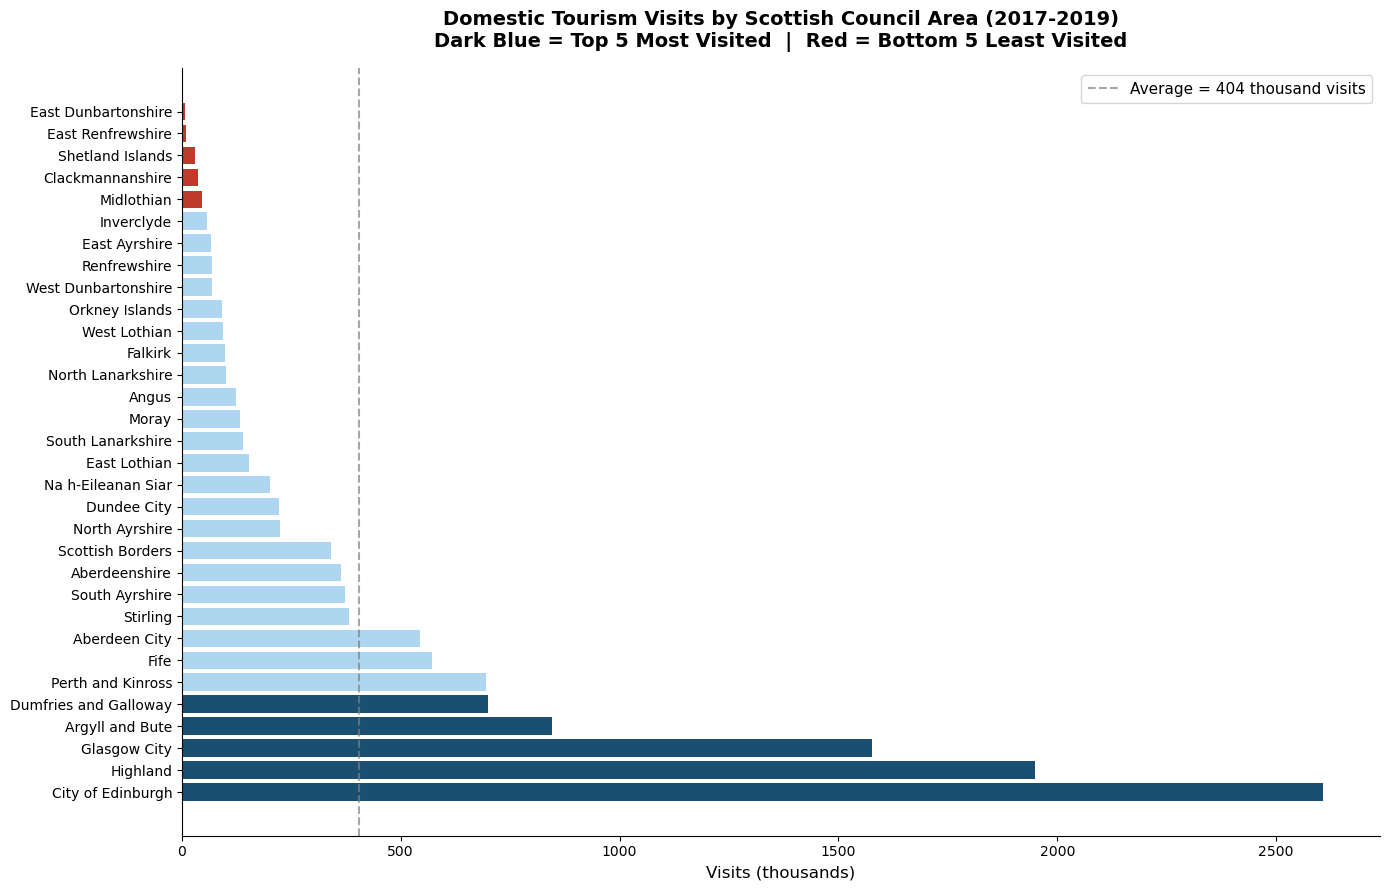

In [19]:
# ============================================================
#  FIGURE 1: Regional Visits Ranking
# Compares domestic tourism visit volume across all 32
# Scottish council areas using the most recent time period
# ============================================================

# Use most recent time period available
latest_period = df_visits['DateCode'].max()
df_latest = df_visits[df_visits['DateCode'] == latest_period].sort_values('Value', ascending=False)

# Colour: top 5 dark blue | bottom 5 red | rest light blue
colours = []
for i in range(len(df_latest)):
    if i < 5:
        colours.append('#1B4F72')
    elif i >= len(df_latest) - 5:
        colours.append('#C0392B')
    else:
        colours.append('#AED6F1')

fig, ax = plt.subplots(figsize=(14, 9))
ax.barh(df_latest['Region'], df_latest['Value'], color=colours)
ax.axvline(x=df_latest['Value'].mean(), color='grey', linestyle='--',
           alpha=0.7, label=f'Average = {df_latest["Value"].mean():.0f} thousand visits')
ax.set_xlabel('Visits (thousands)', fontsize=12)
ax.set_title(
    f'Domestic Tourism Visits by Scottish Council Area ({latest_period})\n'
    'Dark Blue = Top 5 Most Visited  |  Red = Bottom 5 Least Visited',
    fontsize=14, fontweight='bold', pad=15
)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('chart1_regional_visits.png', dpi=150, bbox_inches='tight')
plt.show()

### FIGURE 1: Interpretation

The City of Edinburgh recorded the highest domestic tourism 
visit volume at 2,607 thousand visits during the 2017–2019 
period, followed by Highland (1,950 thousand) and Glasgow 
City (1,577 thousand). At the opposite end of the 
distribution, East Dunbartonshire recorded only 7 thousand 
visits, producing a regional imbalance ratio of 372:1 
between the most and least visited council areas.

This extreme concentration of visitor activity within three 
council areas demonstrates a structurally significant 
regional imbalance. The majority of Scotland's 32 council 
areas receive visit volumes well below the regional average, 
indicating that tourism economic benefits are distributed 
profoundly unequally across Scotland's local authority areas.

In [20]:
# Get visits and spend for latest period
df_v = df_visits[
    df_visits['DateCode'] == latest_period
][['Region', 'Value']].rename(columns={'Value': 'Visits'})

df_s = df_spend[
    df_spend['DateCode'] == latest_period
][['Region', 'Value']].rename(columns={'Value': 'Spend_£m'})

# Merge visits and spend
df_eff = pd.merge(df_v, df_s, on='Region')

# Calculate spend per visit in £
df_eff['Spend_per_Visit_£'] = (
    df_eff['Spend_£m'] / df_eff['Visits']) * 1000

# Sort highest to lowest
df_eff = df_eff.sort_values(
    'Spend_per_Visit_£', ascending=False).reset_index(drop=True)

print(f"✅ Spend per visit data ready")
print(f"Regions: {len(df_eff)}")
print(f"Highest spend per visit: "
      f"£{df_eff['Spend_per_Visit_£'].iloc[0]:.0f} "
      f"({df_eff['Region'].iloc[0]})")

✅ Spend per visit data ready
Regions: 32
Highest spend per visit: £413 (Orkney Islands)


In [21]:
# Top and bottom 5 regions by spend per visit
print("TOP 5 HIGHEST SPEND PER VISIT")
print("=" * 50)
display(df_eff[['Region','Visits','Spend_£m','Spend_per_Visit_£']].head(5).reset_index(drop=True).round(2))

print("\nBOTTOM 5 LOWEST SPEND PER VISIT")
print("=" * 50)
display(df_eff[['Region','Visits','Spend_£m','Spend_per_Visit_£']].tail(5).reset_index(drop=True).round(2))

print(f"\nAverage spend per visit: £{df_eff['Spend_per_Visit_£'].mean():.2f}")
print(f"Highest: £{df_eff['Spend_per_Visit_£'].max():.2f} — {df_eff['Region'].iloc[0]}")
print(f"Lowest:  £{df_eff['Spend_per_Visit_£'].min():.2f} — {df_eff['Region'].iloc[-1]}")

TOP 5 HIGHEST SPEND PER VISIT


,Region,Visits,Spend_£m,Spend_per_Visit_£
0,Orkney Islands,92,38,413.04
1,Na h-Eileanan Siar,201,62,308.46
2,City of Edinburgh,2607,728,279.25
3,Highland,1950,492,252.31
4,East Ayrshire,67,16,238.81



BOTTOM 5 LOWEST SPEND PER VISIT


,Region,Visits,Spend_£m,Spend_per_Visit_£
0,West Lothian,95,12,126.32
1,Renfrewshire,68,8,117.65
2,East Renfrewshire,9,1,111.11
3,Midlothian,46,5,108.70
4,Clackmannanshire,38,3,78.95



Average spend per visit: £198.76
Highest: £413.04 — Orkney Islands
Lowest:  £78.95 — Clackmannanshire


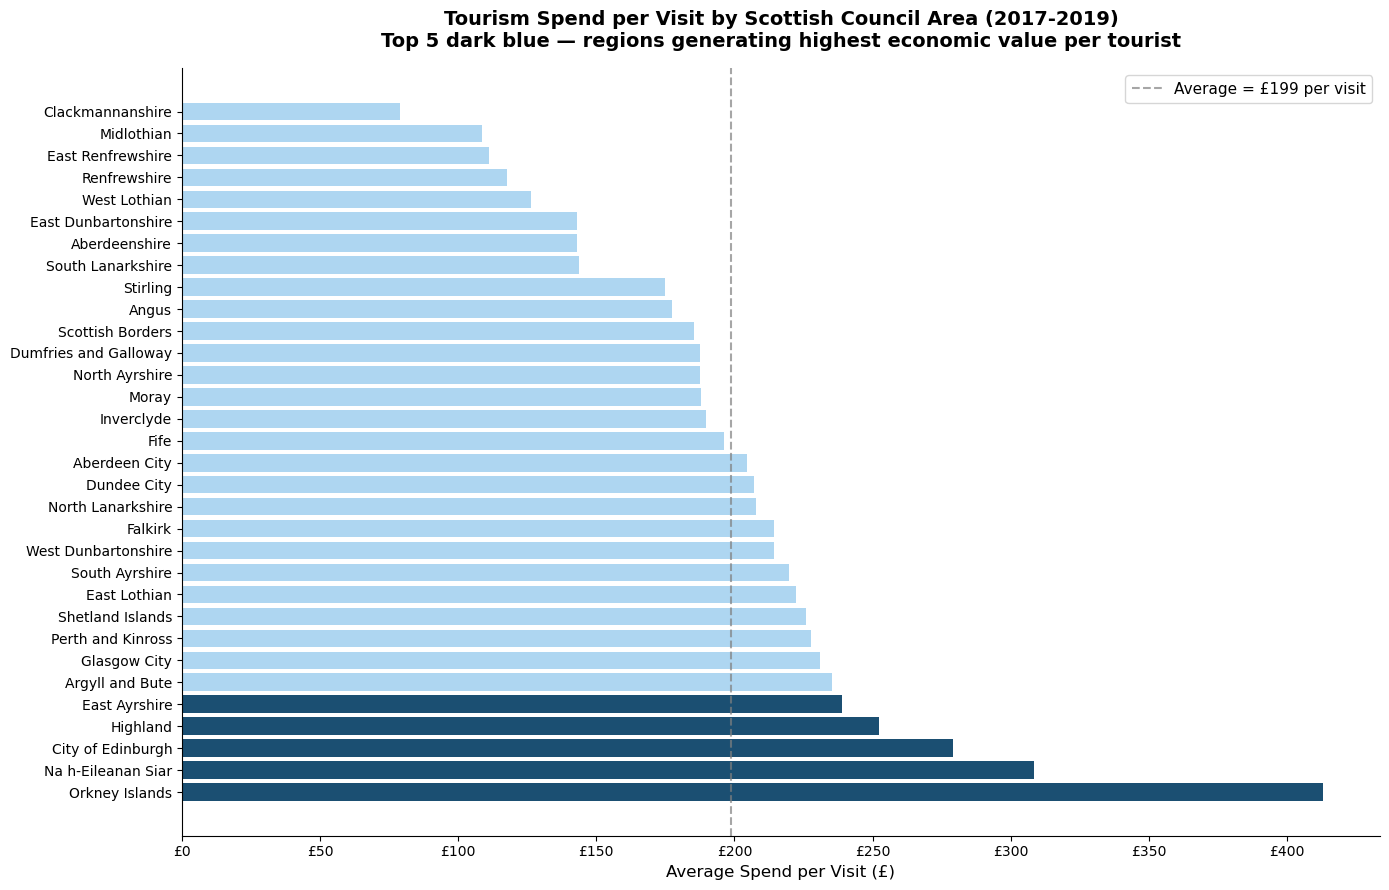

In [22]:
# ============================================================
# FIGURE 2: Spend per Visit by Region
# Measures economic value efficiency: how much each visitor
# spends per trip, identifying high value destinations
#
# Calculation:
#   Spend (£ millions) × 1,000,000 ÷ Visits (thousands) × 1,000
#   Simplified: (Spend_£m ÷ Visits) × 1,000 = £ per visit
# ============================================================

# Merge visits and spend for latest period
df_v = df_visits[df_visits['DateCode'] == latest_period][['Region','Value']].rename(columns={'Value':'Visits'})
df_s = df_spend[df_spend['DateCode'] == latest_period][['Region','Value']].rename(columns={'Value':'Spend_£m'})
df_eff = pd.merge(df_v, df_s, on='Region')

# Calculate spend per visit in £
df_eff['Spend_per_Visit_£'] = (df_eff['Spend_£m'] / df_eff['Visits']) * 1000
df_eff = df_eff.sort_values('Spend_per_Visit_£', ascending=False)

fig, ax = plt.subplots(figsize=(14, 9))
ax.barh(df_eff['Region'], df_eff['Spend_per_Visit_£'],
        color=['#1B4F72' if i < 5 else '#AED6F1' for i in range(len(df_eff))])
ax.axvline(x=df_eff['Spend_per_Visit_£'].mean(), color='grey', linestyle='--',
           alpha=0.7, label=f'Average = £{df_eff["Spend_per_Visit_£"].mean():.0f} per visit')
ax.set_xlabel('Average Spend per Visit (£)', fontsize=12)
ax.set_title(
    f'Tourism Spend per Visit by Scottish Council Area ({latest_period})\n'
    'Top 5 dark blue — regions generating highest economic value per tourist',
    fontsize=14, fontweight='bold', pad=15
)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x:.0f}'))
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('chart2_spend_per_visit.png', dpi=150, bbox_inches='tight')
plt.show()

### FIGURE 2: Tourism Spend per Visit by Scottish Council Area (2017–2019)
**Source:** Scottish Government (2024):- Regional Domestic Tourism

---

**What the chart shows:**
Horizontal bar chart showing average spend per tourist visit 
across all 32 Scottish council areas. Calculated as total 
expenditure (£ millions) divided by total visits (thousand 
visits) multiplied by 1,000 to produce £ per visit.

**Key finding:**
Orkney Islands recorded the highest spend per visit at £413, 
followed by Na h-Eileanan Siar at £308 and City of Edinburgh 
at £279. The island authorities, despite their low visit 
volumes consistently achieve the highest economic value 
per visitor.

**What this means:**
High visitor value and high visitor volume do not necessarily 
coincide. The island authorities generate disproportionately 
high economic output per tourist despite attracting far fewer 
visitors than the urban hubs, suggesting they represent 
high-efficiency targets for tourism development investment.



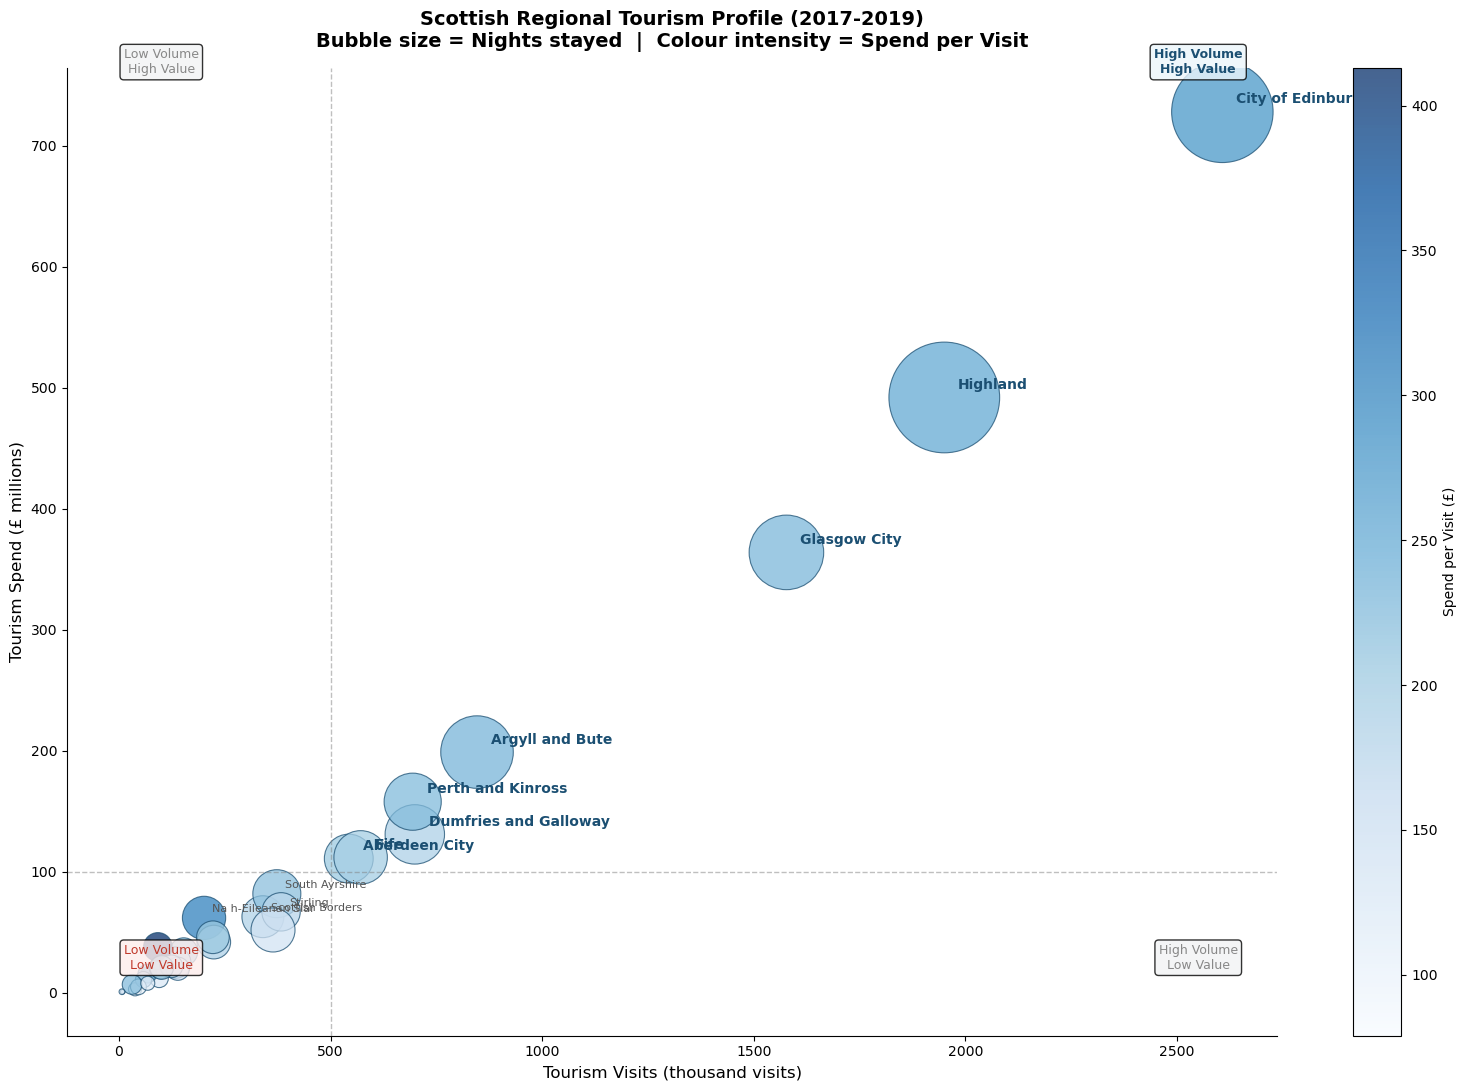

In [23]:
# ============================================================
# FIGURE 3: Regional Tourism Profile Bubble Chart
# Shows three dimensions simultaneously:
#   X-axis  = Visit volume (thousand visits)
#   Y-axis  = Tourism spend (£ millions)
#   Bubble  = Nights stayed (thousand nights)
#   Colour  = Spend per visit (£)
# ============================================================

# Merge visits, spend and nights for latest period
df_v = df_visits[df_visits['DateCode'] == latest_period][['Region','Value']].rename(columns={'Value':'Visits'})
df_s = df_spend[df_spend['DateCode'] == latest_period][['Region','Value']].rename(columns={'Value':'Spend_£m'})
df_n = df_nights[df_nights['DateCode'] == latest_period][['Region','Value']].rename(columns={'Value':'Nights'})

df_bubble = pd.merge(df_v, df_s, on='Region')
df_bubble = pd.merge(df_bubble, df_n, on='Region')
df_bubble['Spend_per_Visit_£'] = (df_bubble['Spend_£m'] / df_bubble['Visits']) * 1000

# Define threshold for labelling
# Regions above threshold get bold labels
# Regions below threshold are shown in table only
threshold_visits = 400

df_high = df_bubble[df_bubble['Visits'] >= threshold_visits]
df_low  = df_bubble[df_bubble['Visits'] <  threshold_visits]

fig, ax = plt.subplots(figsize=(16, 11))

# Plot all bubbles
scatter = ax.scatter(
    df_bubble['Visits'],
    df_bubble['Spend_£m'],
    s=df_bubble['Nights'] * 0.8,
    c=df_bubble['Spend_per_Visit_£'],
    cmap='Blues',
    alpha=0.75,
    edgecolors='#1B4F72',
    linewidths=0.8
)

# Label high profile regions clearly
for _, row in df_high.iterrows():
    ax.annotate(
        row['Region'],
        (row['Visits'], row['Spend_£m']),
        textcoords='offset points',
        xytext=(10, 6),
        fontsize=10,
        fontweight='bold',
        color='#1B4F72'
    )

# For low profile regions — only label if spend > 60
# to avoid the bottom left cluster
for _, row in df_low.iterrows():
    if row['Spend_£m'] > 60:
        ax.annotate(
            row['Region'],
            (row['Visits'], row['Spend_£m']),
            textcoords='offset points',
            xytext=(6, 4),
            fontsize=8,
            color='#555555'
        )

# Quadrant lines based on meaningful thresholds
# Vertical line at 500k visits (clear separation point)
# Horizontal line at £100m spend
ax.axvline(x=500,  color='grey', linestyle='--', alpha=0.5, linewidth=1)
ax.axhline(y=100,  color='grey', linestyle='--', alpha=0.5, linewidth=1)

# Quadrant labels positioned clearly in each corner
ax.text(2550, 760,  'High Volume\nHigh Value',
        fontsize=9, color='#1B4F72', fontweight='bold', ha='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#EBF5FB', alpha=0.8))

ax.text(2550, 20,   'High Volume\nLow Value',
        fontsize=9, color='#888888', ha='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#F2F3F4', alpha=0.8))

ax.text(100,  760,  'Low Volume\nHigh Value',
        fontsize=9, color='#888888', ha='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#F2F3F4', alpha=0.8))

ax.text(100,  20,   'Low Volume\nLow Value',
        fontsize=9, color='#C0392B', ha='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#FDEDEC', alpha=0.8))

ax.set_xlabel('Tourism Visits (thousand visits)', fontsize=12)
ax.set_ylabel('Tourism Spend (£ millions)', fontsize=12)
ax.set_title(
    f'Scottish Regional Tourism Profile ({latest_period})\n'
    'Bubble size = Nights stayed  |  Colour intensity = Spend per Visit',
    fontsize=14, fontweight='bold', pad=15
)
plt.colorbar(scatter, ax=ax, label='Spend per Visit (£)')
plt.tight_layout()
plt.savefig('chart3_regional_bubble.png', dpi=150, bbox_inches='tight')
plt.show()

### Figure 3: Scottish Regional Tourism Profile (2017–2019)
**Source:** Scottish Government (2024):- Regional Domestic Tourism

---

**What the chart shows:**
Multi-dimensional bubble chart showing all 32 Scottish 
council areas simultaneously across three dimensions:
- X-axis: Visit volume (thousand visits)
- Y-axis: Tourism spend (£ millions)
- Bubble size: Nights stayed (thousand nights)
- Colour intensity: Spend per visit (£)

**Key finding:**
Edinburgh, Highland and Glasgow occupy a distinct high 
volume, high value quadrant completely separated from the 
remaining 29 council areas. Edinburgh's large bubble 
indicates the longest average stays. The majority of council 
areas cluster in the lower left quadrant with low visits, 
low spend and small bubbles indicating short stays.

**What this means:**
Scotland's regional tourism landscape has a clear three-tier 
structure, dominant hubs, high-value island destinations 
and a large cluster of underperforming regions. This visual 
pattern directly motivates the K-Means clustering analysis 
in Section 8 which formalises this three-tier classification 
using machine learning.

In [24]:
# Summary statistics from the bubble chart data
print("REGIONAL TOURISM PROFILE SUMMARY")
print("=" * 55)
display(df_bubble[['Region','Visits','Spend_£m','Nights','Spend_per_Visit_£']]
        .sort_values('Spend_£m', ascending=False)
        .reset_index(drop=True)
        .round(2))

print(f"\nTotal visits across all regions:  {df_bubble['Visits'].sum():,.0f} thousand")
print(f"Total spend across all regions:   £{df_bubble['Spend_£m'].sum():,.0f} million")
print(f"Total nights across all regions:  {df_bubble['Nights'].sum():,.0f} thousand")

REGIONAL TOURISM PROFILE SUMMARY


,Region,Visits,Spend_£m,Nights,Spend_per_Visit_£
0,City of Edinburgh,2607,728,6671,279.25
1,Highland,1950,492,7944,252.31
2,Glasgow City,1577,364,3602,230.82
3,Argyll and Bute,846,199,3411,235.22
4,Perth and Kinross,694,158,2116,227.67
5,Dumfries and Galloway,699,131,2288,187.41
6,Fife,571,112,1853,196.15
7,Aberdeen City,543,111,1546,204.42
8,South Ayrshire,373,82,1493,219.84
9,Stirling,383,67,955,174.93



Total visits across all regions:  12,923 thousand
Total spend across all regions:   £2,969 million
Total nights across all regions:  41,430 thousand


---
## Section 5: Domestic Overnight Tourism Analysis

### Dataset 1: Great Britain Tourism Survey: Overnight Trips
**Source:** VisitScotland (2024b) — GBTS Overnight Trips 
Annual and Quarterly Reports
**Coverage:** Scotland, 2023–2025
**Units:** Trips = millions | Spend = £ millions | 
Nights = millions | Spend per Trip = £

---

This section analyses domestic overnight tourism patterns 
in Scotland using summary statistics manually compiled from 
the GBTS Overnight quarterly and annual reports. Since the 
GBTS data is published in PDF format rather than as 
downloadable CSV or Excel files, key statistics have been 
extracted and structured into analytical dataframes within 
this notebook, with all figures cross-referenced against 
the original published reports to ensure accuracy.

Two analyses are conducted in this section:

- **Figure 4:** Annual overnight tourism — volume vs value 
  trend (2023–2024)
- **Figure 5:** Quarterly overnight tourism seasonality 
  (2025)

### Key Variables
| Variable | Description | Unit |
|----------|-------------|------|
| Trips_m | Overnight trip volume | Millions |
| Spend_£bn | Total visitor expenditure | £ Billions |
| Nights_m | Total nights stayed | Millions |
| Spend_per_Trip | Average spend per trip | £ |
| Spend_per_Night | Average spend per night | £ |

In [25]:
# Annual Scotland data 2023 and 2024
gbts_annual = pd.DataFrame({
    'Year'              : [2023,  2024],
    'Trips_m'           : [12.4,  10.6],
    'Spend_£bn'         : [3.19,  3.34],
    'Nights_m'          : [35.4,  29.5],
    'Spend_per_Trip_£'  : [258,   315],
    'Spend_per_Night_£' : [90,    113],
    'Nights_per_Trip'   : [2.9,   2.8]
})

# Quarterly Scotland data 2025
gbts_quarterly = pd.DataFrame({
    'Quarter'           : ['Q1 2025', 'Q2 2025', 'Q3 2025'],
    'Trips_m'           : [2.2,       2.2,       3.3],
    'Spend_£m'          : [752,       747,       1286],
    'Nights_m'          : [6.1,       None,      10.4],
    'Spend_per_Trip_£'  : [342,       None,      384]
})

print("✅ GBTS Overnight data loaded")
print("\nAnnual data:")
display(gbts_annual)

print("\nQuarterly 2025 data:")
display(gbts_quarterly)

✅ GBTS Overnight data loaded

Annual data:


,Year,Trips_m,Spend_£bn,Nights_m,Spend_per_Trip_£,Spend_per_Night_£,Nights_per_Trip
0,2023,12.4,3.19,35.4,258,90,2.9
1,2024,10.6,3.34,29.5,315,113,2.8



Quarterly 2025 data:


,Quarter,Trips_m,Spend_£m,Nights_m,Spend_per_Trip_£
0,Q1 2025,2.2,752,6.1,342.0
1,Q2 2025,2.2,747,NaN,NaN
2,Q3 2025,3.3,1286,10.4,384.0


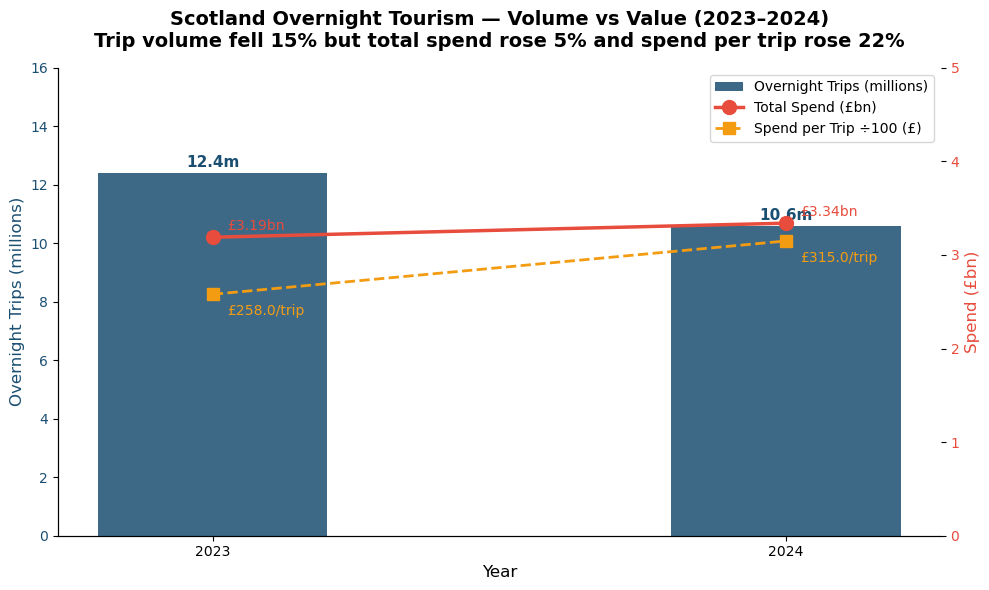

In [26]:
# ============================================================
# FIGURE 4: Annual Overnight Tourism Trends
# Dual axis chart showing:
#   Bars    = Trip volume (millions) — left axis
#   Line 1  = Total spend (£bn) — right axis
#   Line 2  = Spend per trip (£) — right axis
# Illustrates the "fewer trips but higher spending" pattern
# ============================================================

fig, ax1 = plt.subplots(figsize=(10, 6))

# Left axis — trip volume bars
bars = ax1.bar(
    gbts_annual['Year'],
    gbts_annual['Trips_m'],
    width=0.4,
    color='#1B4F72',
    alpha=0.85,
    label='Overnight Trips (millions)'
)

# Add value labels on bars
for bar in bars:
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f'{bar.get_height()}m',
        ha='center', fontsize=11, fontweight='bold', color='#1B4F72'
    )

ax1.set_ylabel('Overnight Trips (millions)', color='#1B4F72', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#1B4F72')
ax1.set_ylim(0, 16)
ax1.set_xticks([2023, 2024])
ax1.set_xlabel('Year', fontsize=12)

# Right axis — spend lines
ax2 = ax1.twinx()

ax2.plot(
    gbts_annual['Year'],
    gbts_annual['Spend_£bn'],
    color='#E74C3C',
    marker='o',
    linewidth=2.5,
    markersize=10,
    label='Total Spend (£bn)'
)

ax2.plot(
    gbts_annual['Year'],
    gbts_annual['Spend_per_Trip_£'] / 100,
    color='#F39C12',
    marker='s',
    linewidth=2,
    markersize=8,
    linestyle='--',
    label='Spend per Trip ÷100 (£)'
)

# Add value labels on lines
for i, row in gbts_annual.iterrows():
    ax2.annotate(
        f'£{row["Spend_£bn"]}bn',
        (row['Year'], row['Spend_£bn']),
        textcoords='offset points',
        xytext=(10, 5),
        fontsize=10,
        color='#E74C3C'
    )
    ax2.annotate(
        f'£{row["Spend_per_Trip_£"]}/trip',
        (row['Year'], row['Spend_per_Trip_£'] / 100),
        textcoords='offset points',
        xytext=(10, -15),
        fontsize=10,
        color='#F39C12'
    )

ax2.set_ylabel('Spend (£bn)', color='#E74C3C', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#E74C3C')
ax2.set_ylim(0, 5)

ax1.set_title(
    'Scotland Overnight Tourism — Volume vs Value (2023–2024)\n'
    'Trip volume fell 15% but total spend rose 5% and spend per trip rose 22%',
    fontsize=14, fontweight='bold', pad=15
)

# Combined legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=10)
plt.tight_layout()
plt.savefig('chart4_annual_overnight_trends.png', dpi=150, bbox_inches='tight')
plt.show()

### Figure 4: Scotland Overnight Tourism — Volume vs Value (2023–2024)
**Source:** VisitScotland (2024b) — GBTS Overnight Trips Annual Report

---

**What the chart shows:**
Dual-axis chart comparing overnight trip volume (blue bars, 
left axis) and total visitor spend (red line, right axis) 
for 2023 and 2024. The dashed orange line shows spend per 
trip divided by 100 for scale comparability.

**Key finding:**
Overnight trips declined by 14.5% from 12.4 million to 
10.6 million between 2023 and 2024, while total spend 
increased by 4.7% from £3.19 billion to £3.34 billion. 
Average spend per trip rose by 22.1% from £258 to £315.

**What this means:**
Scotland's overnight tourism is undergoing a structural 
shift toward fewer but higher-value visits. A yield-focused 
analytical perspective reveals improving economic performance 
despite declining trip volumes directly supporting 
Recommendation 4 on adopting a visitor yield framework.

In [27]:
# ============================================================
# Calculate percentage changes
# ============================================================

trips_change  = (10.6 - 12.4) / 12.4 * 100
spend_change  = (3.34 - 3.19) / 3.19 * 100
spt_change    = (315  - 258)  / 258  * 100
nights_change = (29.5 - 35.4) / 35.4 * 100
spn_change    = (113  - 90)   / 90   * 100

print("ANNUAL OVERNIGHT TOURISM — KEY CHANGES 2023 TO 2024")
print("=" * 55)
print(f"Overnight trips:       {12.4}m → {10.6}m  ({trips_change:.1f}%)")
print(f"Total spend:           £{3.19}bn → £{3.34}bn (+{spend_change:.1f}%)")
print(f"Spend per trip:        £{258} → £{315}    (+{spt_change:.1f}%)")
print(f"Nights stayed:         {35.4}m → {29.5}m  ({nights_change:.1f}%)")
print(f"Spend per night:       £{90} → £{113}     (+{spn_change:.1f}%)")
print(f"\nKey narrative:")
print(f"Despite a {trips_change:.1f}% fall in trip volume, total spend")
print(f"grew by +{spend_change:.1f}% — driven by a +{spt_change:.1f}% rise")
print(f"in average spend per trip from £258 to £315.")
print(f"Scotland's tourism is shifting toward fewer but")
print(f"higher-value visits.")

ANNUAL OVERNIGHT TOURISM — KEY CHANGES 2023 TO 2024
Overnight trips:       12.4m → 10.6m  (-14.5%)
Total spend:           £3.19bn → £3.34bn (+4.7%)
Spend per trip:        £258 → £315    (+22.1%)
Nights stayed:         35.4m → 29.5m  (-16.7%)
Spend per night:       £90 → £113     (+25.6%)

Key narrative:
Despite a -14.5% fall in trip volume, total spend
grew by +4.7% — driven by a +22.1% rise
in average spend per trip from £258 to £315.
Scotland's tourism is shifting toward fewer but
higher-value visits.


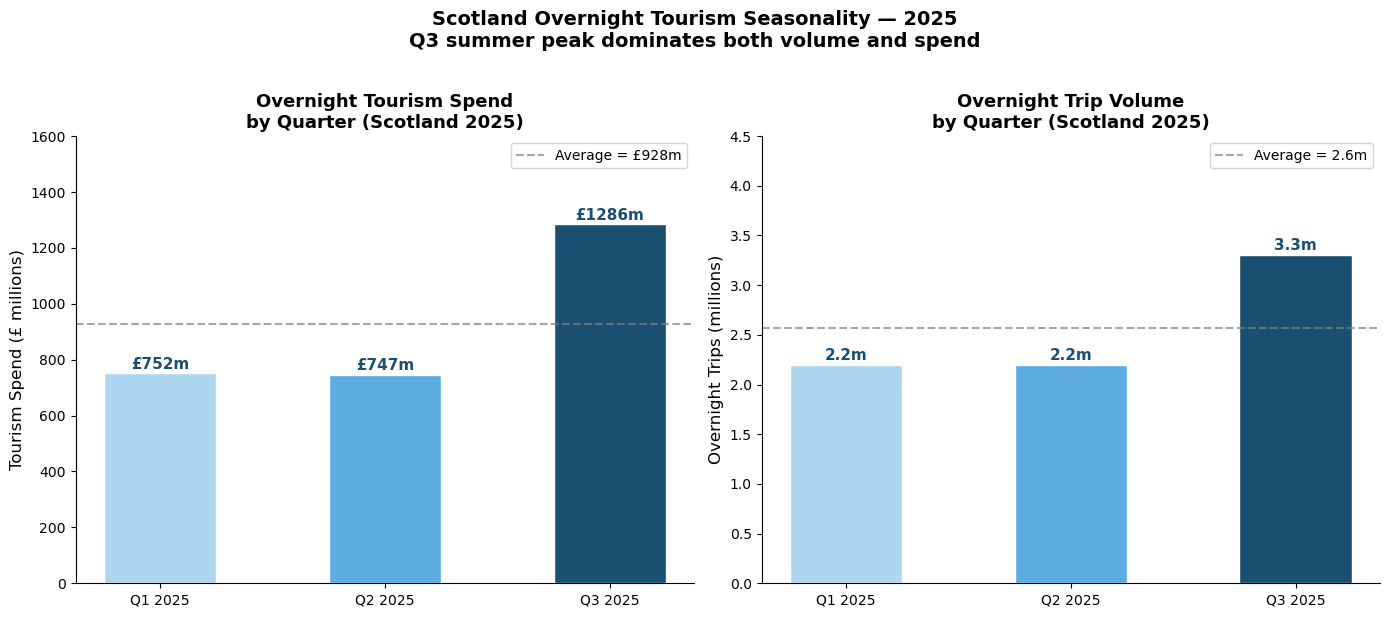

In [28]:
# ============================================================
# FIGURE 5: Overnight Tourism Seasonality
# Shows quarterly spend distribution across 2025
# Illustrates the summer peak and shoulder season weakness
# Q1 = January-March | Q2 = April-June | Q3 = July-September
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Left chart: Spend by quarter ---
colours_q = ['#AED6F1', '#5DADE2', '#1B4F72']

bars = axes[0].bar(
    gbts_quarterly['Quarter'],
    gbts_quarterly['Spend_£m'],
    color=colours_q,
    edgecolor='white',
    linewidth=1,
    width=0.5
)

# Value labels on bars
for bar, val in zip(bars, gbts_quarterly['Spend_£m']):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f'£{val}m',
        ha='center', fontsize=11, fontweight='bold', color='#1B4F72'
    )

# Average line
avg_spend = gbts_quarterly['Spend_£m'].mean()
axes[0].axhline(
    y=avg_spend, color='grey', linestyle='--', alpha=0.7,
    label=f'Average = £{avg_spend:.0f}m'
)

axes[0].set_ylabel('Tourism Spend (£ millions)', fontsize=12)
axes[0].set_ylim(0, 1600)
axes[0].set_title('Overnight Tourism Spend\nby Quarter (Scotland 2025)',
                  fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)

# --- Right chart: Trip volume by quarter ---
bars2 = axes[1].bar(
    gbts_quarterly['Quarter'],
    gbts_quarterly['Trips_m'],
    color=colours_q,
    edgecolor='white',
    linewidth=1,
    width=0.5
)

# Value labels on bars
for bar, val in zip(bars2, gbts_quarterly['Trips_m']):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f'{val}m',
        ha='center', fontsize=11, fontweight='bold', color='#1B4F72'
    )

# Average line
avg_trips = gbts_quarterly['Trips_m'].mean()
axes[1].axhline(
    y=avg_trips, color='grey', linestyle='--', alpha=0.7,
    label=f'Average = {avg_trips:.1f}m'
)

axes[1].set_ylabel('Overnight Trips (millions)', fontsize=12)
axes[1].set_ylim(0, 4.5)
axes[1].set_title('Overnight Trip Volume\nby Quarter (Scotland 2025)',
                  fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)

plt.suptitle(
    'Scotland Overnight Tourism Seasonality — 2025\n'
    'Q3 summer peak dominates both volume and spend',
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig('chart5_overnight_seasonality.png', dpi=150, bbox_inches='tight')
plt.show()

### Figure 5: Scotland Overnight Tourism Seasonality by Quarter (2025)
**Source:** VisitScotland (2024b) — GBTS Overnight Trips Quarterly Reports

---

**What the chart shows:**
Two-panel bar chart showing overnight tourism spend 
(left panel) and trip volume (right panel) by quarter 
for January to September 2025. Colour intensity increases 
from Q1 (lightest) to Q3 (darkest) to reinforce the 
seasonal pattern visually.

**Key finding:**
Quarter 3 generated £1,286 million in spend, 46.2% of 
the year-to-date total and 1.71 times the spend of either 
Quarter 1 (£752 million) or Quarter 2 (£747 million). 
Quarter 3 visitors also spent more per trip (£390) than 
Q1 (£342) or Q2 (£340).

**What this means:**
Scotland's overnight tourism seasonality challenge is 
characterised by a sharp summer spike rather than a 
gradual seasonal gradient with summer concentration 
driven by both higher visitor volumes and higher 
individual spending simultaneously. The £534 million 
spend gap between Q1 and Q3 quantifies the economic 
opportunity of shoulder season development addressed 
in Recommendation 2.

In [29]:
# ============================================================
# Seasonality analysis: quantifying the peak vs trough gap
# ============================================================

q1_spend = gbts_quarterly['Spend_£m'].iloc[0]
q2_spend = gbts_quarterly['Spend_£m'].iloc[1]
q3_spend = gbts_quarterly['Spend_£m'].iloc[2]

q1_trips = gbts_quarterly['Trips_m'].iloc[0]
q2_trips = gbts_quarterly['Trips_m'].iloc[1]
q3_trips = gbts_quarterly['Trips_m'].iloc[2]

total_spend = gbts_quarterly['Spend_£m'].sum()
total_trips = gbts_quarterly['Trips_m'].sum()

print("OVERNIGHT TOURISM SEASONALITY — 2025")
print("=" * 50)
print(f"\nSpend by quarter:")
print(f"  Q1 (Jan-Mar): £{q1_spend}m  ({q1_spend/total_spend*100:.1f}% of YTD total)")
print(f"  Q2 (Apr-Jun): £{q2_spend}m  ({q2_spend/total_spend*100:.1f}% of YTD total)")
print(f"  Q3 (Jul-Sep): £{q3_spend}m ({q3_spend/total_spend*100:.1f}% of YTD total)")

print(f"\nTrips by quarter:")
print(f"  Q1 (Jan-Mar): {q1_trips}m  ({q1_trips/total_trips*100:.1f}% of YTD total)")
print(f"  Q2 (Apr-Jun): {q2_trips}m  ({q2_trips/total_trips*100:.1f}% of YTD total)")
print(f"  Q3 (Jul-Sep): {q3_trips}m  ({q3_trips/total_trips*100:.1f}% of YTD total)")

print(f"\nSeasonality ratios:")
print(f"  Q3 spend vs Q1 spend: {q3_spend/q1_spend:.2f}x larger")
print(f"  Q3 trips vs Q1 trips: {q3_trips/q1_trips:.2f}x larger")
print(f"  Q3 alone accounts for {q3_spend/total_spend*100:.1f}% of YTD spend")

print(f"\nShoulder season gap (Q1 vs Q3):")
print(f"  Spend shortfall in Q1 vs Q3: £{q3_spend - q1_spend}m")
print(f"  Closing this gap represents significant economic opportunity")

OVERNIGHT TOURISM SEASONALITY — 2025

Spend by quarter:
  Q1 (Jan-Mar): £752m  (27.0% of YTD total)
  Q2 (Apr-Jun): £747m  (26.8% of YTD total)
  Q3 (Jul-Sep): £1286m (46.2% of YTD total)

Trips by quarter:
  Q1 (Jan-Mar): 2.2m  (28.6% of YTD total)
  Q2 (Apr-Jun): 2.2m  (28.6% of YTD total)
  Q3 (Jul-Sep): 3.3m  (42.9% of YTD total)

Seasonality ratios:
  Q3 spend vs Q1 spend: 1.71x larger
  Q3 trips vs Q1 trips: 1.50x larger
  Q3 alone accounts for 46.2% of YTD spend

Shoulder season gap (Q1 vs Q3):
  Spend shortfall in Q1 vs Q3: £534m
  Closing this gap represents significant economic opportunity


In [30]:
# ============================================================
# Spend per trip by quarter
# Spend is in £ millions | Trips is in millions
# Spend per trip = Spend_£m / Trips_m (both in same units)
# Result = £ per trip
# ============================================================

gbts_quarterly['Spend_per_Trip'] = (
    (gbts_quarterly['Spend_£m'] * 1_000_000) /
    (gbts_quarterly['Trips_m'] * 1_000_000)
).round(0)

print("SPEND PER TRIP BY QUARTER")
print("=" * 45)
display(gbts_quarterly[['Quarter', 'Trips_m', 'Spend_£m', 'Spend_per_Trip']]
        .round(1))

highest_q = gbts_quarterly.loc[gbts_quarterly['Spend_per_Trip'].idxmax(), 'Quarter']
lowest_q  = gbts_quarterly.loc[gbts_quarterly['Spend_per_Trip'].idxmin(), 'Quarter']
highest_v = gbts_quarterly['Spend_per_Trip'].max()
lowest_v  = gbts_quarterly['Spend_per_Trip'].min()

print(f"\nHighest spend per trip: £{highest_v:.0f} — {highest_q}")
print(f"Lowest spend per trip:  £{lowest_v:.0f}  — {lowest_q}")
print(f"\nQ3 visitors spend £{highest_v - lowest_v:.0f} more per trip than Q2 visitors")
print(f"Summer visitors are not just more numerous — they spend more per trip too")

SPEND PER TRIP BY QUARTER


,Quarter,Trips_m,Spend_£m,Spend_per_Trip
0,Q1 2025,2.2,752,342.0
1,Q2 2025,2.2,747,340.0
2,Q3 2025,3.3,1286,390.0



Highest spend per trip: £390 — Q3 2025
Lowest spend per trip:  £340  — Q2 2025

Q3 visitors spend £50 more per trip than Q2 visitors
Summer visitors are not just more numerous — they spend more per trip too


---
## Section 6: Domestic Day Visit Analysis

### Dataset 2: Great Britain Day Visits Survey (GBDVS)
**Source:** VisitScotland (2024a) -  GBTS Day Visits Annual 
and Quarterly Reports
**Coverage:** Scotland, 2024–2025
**Units:** Visits = millions | Spend = £ millions | 
Spend per Visit = £

---

This section analyses domestic day visit patterns in 
Scotland using summary statistics manually compiled from 
the GBDVS quarterly and annual reports. As with the 
overnight dataset, GBDVS data is published in PDF format 
and key statistics have been extracted and structured into 
analytical dataframes, with all figures cross-referenced 
against the original published reports.

Two analyses are conducted in this section:

- **Figure 6:** Quarterly day visit seasonality - volume 
  and spend (2025)
- **Figure 7:** Overnight vs day visit spend comparison - 
  substitution effect analysis (2025)

### Key Variables
| Variable | Description | Unit |
|----------|-------------|------|
| DayVisits_m | Day visit volume | Millions |
| Spend_£m | Total day visit expenditure | £ Millions |
| Spend_per_Visit | Average spend per day visit | £ |

### Relationship to Section 5
The day visit data in this section is analysed alongside 
the overnight data from Section 5 to investigate the 
substitution effect, the phenomenon whereby day visit 
spend compensates for overnight tourism weakness during 
shoulder seasons.

In [31]:
# Annual Scotland data 2024
gbdv_annual = pd.DataFrame({
    'Year'                  : [2024],
    'Tourism_DayVisits_m'   : [76.8],
    'Spend_£bn'             : [4.03],
    'Avg_Spend_per_Visit'   : [52]
})

# Quarterly Scotland data 2025
gbdv_quarterly = pd.DataFrame({
    'Quarter'       : ['Q1 2025', 'Q2 2025', 'Q3 2025'],
    'DayVisits_m'   : [16.5,      21.4,      25.9],
    'Spend_£m'      : [884,       959,       1242]
})

# Calculate spend per day visit
gbdv_quarterly['Spend_per_Visit'] = (
    (gbdv_quarterly['Spend_£m'] * 1_000_000) /
    (gbdv_quarterly['DayVisits_m'] * 1_000_000)
).round(2)

print("✅ GBTS Day Visits data loaded")
print("\nAnnual data 2024:")
display(gbdv_annual)
print("\nQuarterly data 2025:")
display(gbdv_quarterly)

✅ GBTS Day Visits data loaded

Annual data 2024:


,Year,Tourism_DayVisits_m,Spend_£bn,Avg_Spend_per_Visit
0,2024,76.8,4.03,52



Quarterly data 2025:


,Quarter,DayVisits_m,Spend_£m,Spend_per_Visit
0,Q1 2025,16.5,884,53.58
1,Q2 2025,21.4,959,44.81
2,Q3 2025,25.9,1242,47.95


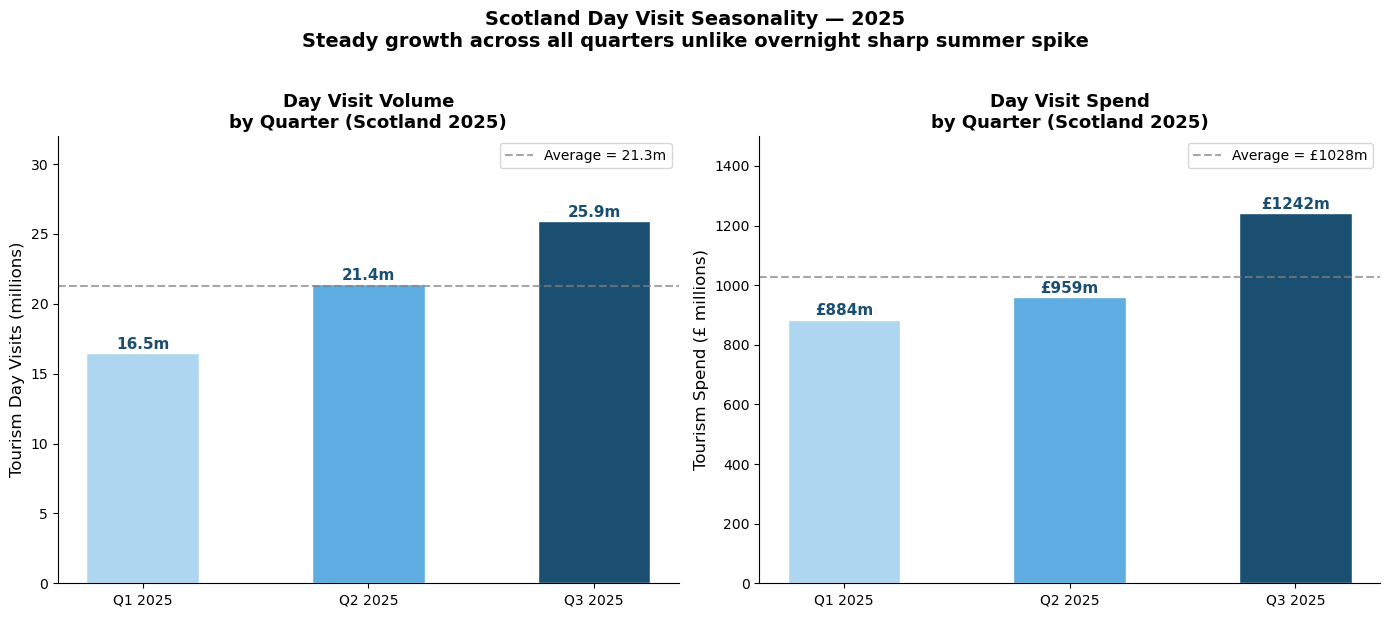

In [32]:
# ============================================================
# FIGURE 6: Day Visit Seasonality
# Shows quarterly distribution of day visit volume and spend
# Compares seasonal pattern with overnight tourism
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colours_q = ['#AED6F1', '#5DADE2', '#1B4F72']

# --- Left chart: Day visit volume ---
bars1 = axes[0].bar(
    gbdv_quarterly['Quarter'],
    gbdv_quarterly['DayVisits_m'],
    color=colours_q,
    edgecolor='white',
    linewidth=1,
    width=0.5
)

for bar, val in zip(bars1, gbdv_quarterly['DayVisits_m']):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f'{val}m',
        ha='center', fontsize=11, fontweight='bold', color='#1B4F72'
    )

avg_visits = gbdv_quarterly['DayVisits_m'].mean()
axes[0].axhline(
    y=avg_visits, color='grey', linestyle='--', alpha=0.7,
    label=f'Average = {avg_visits:.1f}m'
)
axes[0].set_ylabel('Tourism Day Visits (millions)', fontsize=12)
axes[0].set_ylim(0, 32)
axes[0].set_title('Day Visit Volume\nby Quarter (Scotland 2025)',
                  fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)

# --- Right chart: Day visit spend ---
bars2 = axes[1].bar(
    gbdv_quarterly['Quarter'],
    gbdv_quarterly['Spend_£m'],
    color=colours_q,
    edgecolor='white',
    linewidth=1,
    width=0.5
)

for bar, val in zip(bars2, gbdv_quarterly['Spend_£m']):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f'£{val}m',
        ha='center', fontsize=11, fontweight='bold', color='#1B4F72'
    )

avg_spend = gbdv_quarterly['Spend_£m'].mean()
axes[1].axhline(
    y=avg_spend, color='grey', linestyle='--', alpha=0.7,
    label=f'Average = £{avg_spend:.0f}m'
)
axes[1].set_ylabel('Tourism Spend (£ millions)', fontsize=12)
axes[1].set_ylim(0, 1500)
axes[1].set_title('Day Visit Spend\nby Quarter (Scotland 2025)',
                  fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)

plt.suptitle(
    'Scotland Day Visit Seasonality — 2025\n'
    'Steady growth across all quarters unlike overnight sharp summer spike',
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig('chart6_dayvisits_seasonality.png', dpi=150, bbox_inches='tight')
plt.show()

### Figure 6: Scotland Day Visit Seasonality by Quarter (2025)
**Source:** VisitScotland (2024a) — GBTS Day Visits Quarterly Reports

---

**What the chart shows:**
Two-panel bar chart showing domestic day visit volume 
(left panel) and day visit spend (right panel) by quarter 
for January to September 2025.

**Key finding:**
Day visits showed a more gradual seasonal distribution than 
overnight tourism, Q3 to Q1 spend ratio of 1.40 compared 
to 1.71 for overnight. Quarter 1 recorded the highest 
average spend per day visit at £53.58, more than Q2 
(£44.81) or Q3 (£47.95).

**What this means:**
Day visits are inherently less seasonally concentrated than 
overnight tourism, likely reflecting their lower cost and 
commitment threshold. The counterintuitive finding that 
winter day visitors spend most per visit suggests that 
shoulder season day visit campaigns targeting quality 
experiences may deliver stronger per-visitor returns than 
summer volume campaigns.

In [33]:
# ============================================================
# Seasonality analysis for day visits
# Compare with overnight ratios for contrast
# ============================================================

q1_dv_spend = gbdv_quarterly['Spend_£m'].iloc[0]
q2_dv_spend = gbdv_quarterly['Spend_£m'].iloc[1]
q3_dv_spend = gbdv_quarterly['Spend_£m'].iloc[2]

q1_dv = gbdv_quarterly['DayVisits_m'].iloc[0]
q2_dv = gbdv_quarterly['DayVisits_m'].iloc[1]
q3_dv = gbdv_quarterly['DayVisits_m'].iloc[2]

total_dv_spend = gbdv_quarterly['Spend_£m'].sum()
total_dv       = gbdv_quarterly['DayVisits_m'].sum()

print("DAY VISIT SEASONALITY — 2025")
print("=" * 55)
print(f"\nDay visit volume by quarter:")
print(f"  Q1 (Jan-Mar): {q1_dv}m  ({q1_dv/total_dv*100:.1f}% of YTD total)")
print(f"  Q2 (Apr-Jun): {q2_dv}m  ({q2_dv/total_dv*100:.1f}% of YTD total)")
print(f"  Q3 (Jul-Sep): {q3_dv}m  ({q3_dv/total_dv*100:.1f}% of YTD total)")

print(f"\nDay visit spend by quarter:")
print(f"  Q1 (Jan-Mar): £{q1_dv_spend}m  ({q1_dv_spend/total_dv_spend*100:.1f}% of YTD total)")
print(f"  Q2 (Apr-Jun): £{q2_dv_spend}m  ({q2_dv_spend/total_dv_spend*100:.1f}% of YTD total)")
print(f"  Q3 (Jul-Sep): £{q3_dv_spend}m ({q3_dv_spend/total_dv_spend*100:.1f}% of YTD total)")

print(f"\nSeasonality ratios — Day Visits:")
print(f"  Q3 vs Q1 spend ratio: {q3_dv_spend/q1_dv_spend:.2f}x")
print(f"  Q3 vs Q1 volume ratio: {q3_dv/q1_dv:.2f}x")

print(f"\nComparison with Overnight Tourism:")
print(f"  Overnight Q3 vs Q1 spend ratio: 1.71x")
print(f"  Day Visit Q3 vs Q1 spend ratio: {q3_dv_spend/q1_dv_spend:.2f}x")
print(f"\nDay visits show a more gradual seasonal pattern")
print(f"than overnight tourism — less concentrated in summer")

DAY VISIT SEASONALITY — 2025

Day visit volume by quarter:
  Q1 (Jan-Mar): 16.5m  (25.9% of YTD total)
  Q2 (Apr-Jun): 21.4m  (33.5% of YTD total)
  Q3 (Jul-Sep): 25.9m  (40.6% of YTD total)

Day visit spend by quarter:
  Q1 (Jan-Mar): £884m  (28.7% of YTD total)
  Q2 (Apr-Jun): £959m  (31.1% of YTD total)
  Q3 (Jul-Sep): £1242m (40.3% of YTD total)

Seasonality ratios — Day Visits:
  Q3 vs Q1 spend ratio: 1.40x
  Q3 vs Q1 volume ratio: 1.57x

Comparison with Overnight Tourism:
  Overnight Q3 vs Q1 spend ratio: 1.71x
  Day Visit Q3 vs Q1 spend ratio: 1.40x

Day visits show a more gradual seasonal pattern
than overnight tourism — less concentrated in summer


In [34]:
# ============================================================
# Spend per day visit by quarter
# ============================================================

print("SPEND PER DAY VISIT BY QUARTER")
print("=" * 45)
display(gbdv_quarterly[['Quarter', 'DayVisits_m', 'Spend_£m', 'Spend_per_Visit']]
        .round(2))

highest_q = gbdv_quarterly.loc[gbdv_quarterly['Spend_per_Visit'].idxmax(), 'Quarter']
lowest_q  = gbdv_quarterly.loc[gbdv_quarterly['Spend_per_Visit'].idxmin(), 'Quarter']

print(f"\nHighest spend per day visit: £{gbdv_quarterly['Spend_per_Visit'].max()} — {highest_q}")
print(f"Lowest spend per day visit:  £{gbdv_quarterly['Spend_per_Visit'].min()} — {lowest_q}")
print(f"\nNote: Day visit spend per visit (£{gbdv_quarterly['Spend_per_Visit'].mean():.2f} avg)")
print(f"is significantly lower than overnight spend per trip (£{gbts_quarterly['Spend_per_Trip'].mean():.0f} avg)")
print(f"reflecting the shorter duration of day visits")

SPEND PER DAY VISIT BY QUARTER


,Quarter,DayVisits_m,Spend_£m,Spend_per_Visit
0,Q1 2025,16.5,884,53.58
1,Q2 2025,21.4,959,44.81
2,Q3 2025,25.9,1242,47.95



Highest spend per day visit: £53.58 — Q1 2025
Lowest spend per day visit:  £44.81 — Q2 2025

Note: Day visit spend per visit (£48.78 avg)
is significantly lower than overnight spend per trip (£357 avg)
reflecting the shorter duration of day visits


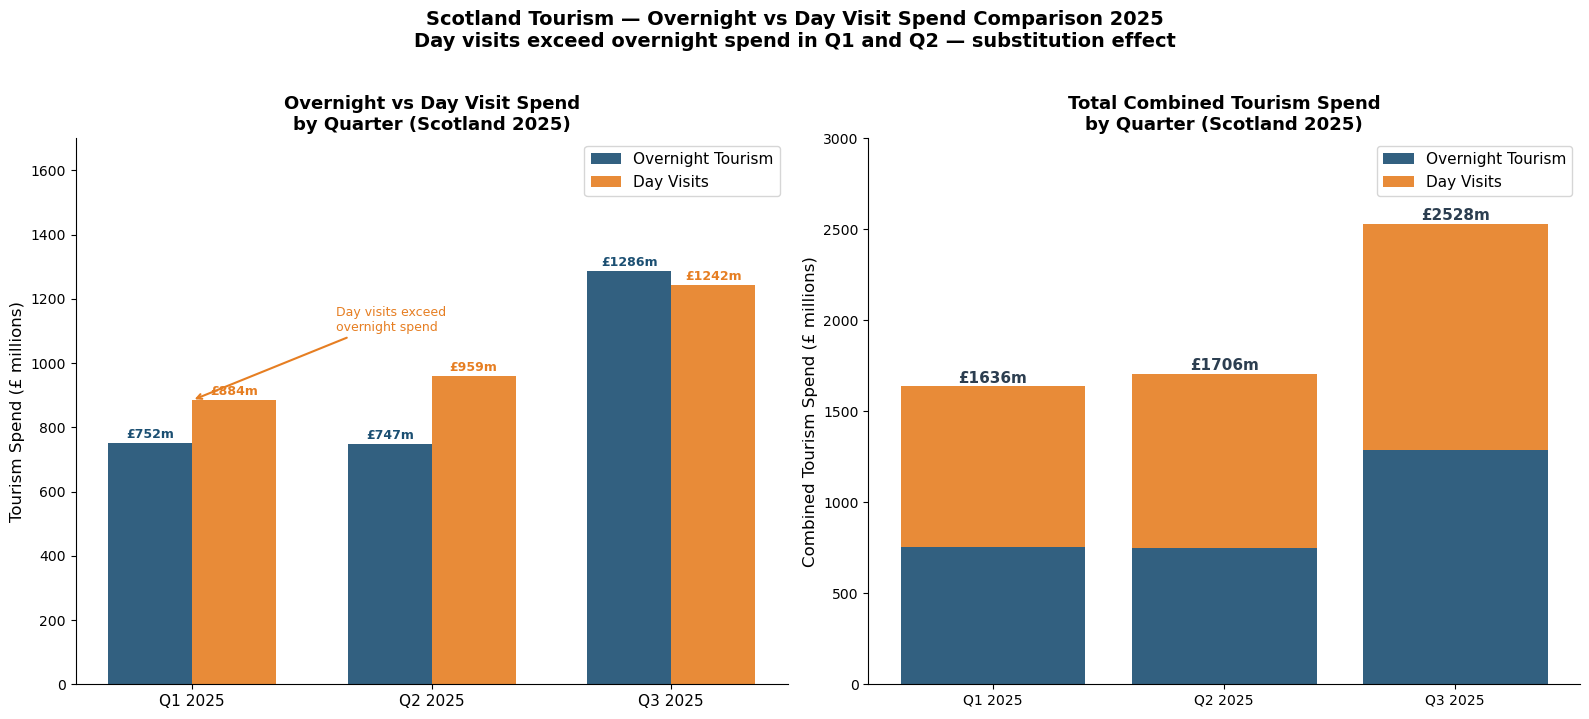

In [35]:
# ============================================================
# FIGURE 7: Overnight vs Day Visit Comparison
# Shows both tourism streams side by side by quarter
# Reveals the substitution effect — when overnight trips
# are lower day visits compensate, keeping total visitor
# economy spend relatively stable
# ============================================================

# Combine both datasets for comparison
comparison = pd.DataFrame({
    'Quarter'           : ['Q1 2025', 'Q2 2025', 'Q3 2025'],
    'Overnight_Spend'   : [752,        747,        1286],
    'DayVisit_Spend'    : [884,        959,        1242],
})

# Calculate total combined spend per quarter
comparison['Total_Spend'] = comparison['Overnight_Spend'] + comparison['DayVisit_Spend']

x     = np.arange(len(comparison['Quarter']))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Left chart: Side by side spend comparison ---
bars1 = axes[0].bar(
    x - width / 2,
    comparison['Overnight_Spend'],
    width,
    label='Overnight Tourism',
    color='#1B4F72',
    alpha=0.9
)
bars2 = axes[0].bar(
    x + width / 2,
    comparison['DayVisit_Spend'],
    width,
    label='Day Visits',
    color='#E67E22',
    alpha=0.9
)

# Value labels
for bar in bars1:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f'£{bar.get_height():.0f}m',
        ha='center', fontsize=9, fontweight='bold', color='#1B4F72'
    )
for bar in bars2:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f'£{bar.get_height():.0f}m',
        ha='center', fontsize=9, fontweight='bold', color='#E67E22'
    )

axes[0].set_xticks(x)
axes[0].set_xticklabels(comparison['Quarter'], fontsize=11)
axes[0].set_ylabel('Tourism Spend (£ millions)', fontsize=12)
axes[0].set_ylim(0, 1700)
axes[0].set_title('Overnight vs Day Visit Spend\nby Quarter (Scotland 2025)',
                  fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)

# Annotation showing day visits exceed overnight in Q1 and Q2
axes[0].annotate(
    'Day visits exceed\novernight spend',
    xy=(0, 884), xytext=(0.6, 1100),
    fontsize=9, color='#E67E22',
    arrowprops=dict(arrowstyle='->', color='#E67E22', lw=1.5)
)

# --- Right chart: Stacked total combined spend ---
axes[1].bar(
    comparison['Quarter'],
    comparison['Overnight_Spend'],
    color='#1B4F72',
    alpha=0.9,
    label='Overnight Tourism'
)
axes[1].bar(
    comparison['Quarter'],
    comparison['DayVisit_Spend'],
    bottom=comparison['Overnight_Spend'],
    color='#E67E22',
    alpha=0.9,
    label='Day Visits'
)

# Total labels on top of stacked bars
for i, row in comparison.iterrows():
    axes[1].text(
        i, row['Total_Spend'] + 20,
        f'£{row["Total_Spend"]}m',
        ha='center', fontsize=11,
        fontweight='bold', color='#2C3E50'
    )

axes[1].set_ylabel('Combined Tourism Spend (£ millions)', fontsize=12)
axes[1].set_ylim(0, 3000)
axes[1].set_title('Total Combined Tourism Spend\nby Quarter (Scotland 2025)',
                  fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11)

plt.suptitle(
    'Scotland Tourism — Overnight vs Day Visit Spend Comparison 2025\n'
    'Day visits exceed overnight spend in Q1 and Q2 — substitution effect',
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig('chart7_overnight_vs_dayvisits.png', dpi=150, bbox_inches='tight')
plt.show()

### Figure 7: Overnight vs Day Visit Spend Comparison (Scotland 2025)
**Source:** VisitScotland (2024a; 2024b) - GBTS Overnight and Day Visit Reports

---

**What the chart shows:**
Two-panel chart comparing overnight and day visit spend 
side by side by quarter (left panel) and as stacked 
combined totals (right panel) for January to September 2025.

**Key finding:**
Day visit spend exceeded overnight tourism spend in both 
Quarter 1 (by £132 million) and Quarter 2 (by £212 million). 
Only in Quarter 3 did overnight marginally exceed day visits 
by £44 million. Across the year-to-date period day visits 
accounted for 52.6% of combined domestic tourism spend.

**What this means:**
A clear substitution effect operates within Scotland's 
domestic visitor economy when overnight trips weaken 
in shoulder seasons day visits compensate. The combined 
quarterly totals (£1,636m Q1, £1,706m Q2, £2,528m Q3) 
demonstrate that the total domestic visitor economy is 
considerably more resilient than overnight data alone 
suggests.

In [36]:
# ============================================================
# Substitution effect analysis
# Quantifies how day visits compensate for overnight weakness
# in shoulder seasons
# ============================================================

print("OVERNIGHT vs DAY VISIT SPEND COMPARISON — 2025")
print("=" * 55)
display(comparison)

print("\nSUBSTITUTION EFFECT ANALYSIS")
print("=" * 55)
for _, row in comparison.iterrows():
    dominant = "Overnight" if row['Overnight_Spend'] > row['DayVisit_Spend'] else "Day Visits"
    diff = abs(row['Overnight_Spend'] - row['DayVisit_Spend'])
    print(f"\n{row['Quarter']}:")
    print(f"  Overnight spend:   £{row['Overnight_Spend']}m")
    print(f"  Day visit spend:   £{row['DayVisit_Spend']}m")
    print(f"  Dominant stream:   {dominant} (by £{diff}m)")
    print(f"  Combined total:    £{row['Total_Spend']}m")

print(f"\nTotal combined spend Jan-Sep 2025:")
print(f"  Overnight:   £{comparison['Overnight_Spend'].sum()}m")
print(f"  Day Visits:  £{comparison['DayVisit_Spend'].sum()}m")
print(f"  Combined:    £{comparison['Total_Spend'].sum()}m")

print(f"\nDay visits as % of combined spend:")
dv_pct = comparison['DayVisit_Spend'].sum() / comparison['Total_Spend'].sum() * 100
print(f"  {dv_pct:.1f}% — day visits are nearly half of total tourism spend")

OVERNIGHT vs DAY VISIT SPEND COMPARISON — 2025


,Quarter,Overnight_Spend,DayVisit_Spend,Total_Spend
0,Q1 2025,752,884,1636
1,Q2 2025,747,959,1706
2,Q3 2025,1286,1242,2528



SUBSTITUTION EFFECT ANALYSIS

Q1 2025:
  Overnight spend:   £752m
  Day visit spend:   £884m
  Dominant stream:   Day Visits (by £132m)
  Combined total:    £1636m

Q2 2025:
  Overnight spend:   £747m
  Day visit spend:   £959m
  Dominant stream:   Day Visits (by £212m)
  Combined total:    £1706m

Q3 2025:
  Overnight spend:   £1286m
  Day visit spend:   £1242m
  Dominant stream:   Overnight (by £44m)
  Combined total:    £2528m

Total combined spend Jan-Sep 2025:
  Overnight:   £2785m
  Day Visits:  £3085m
  Combined:    £5870m

Day visits as % of combined spend:
  52.6% — day visits are nearly half of total tourism spend


---
## Section 7: International Tourism Analysis

### Dataset 3: International Passenger Survey (IPS)
**Source:** Office for National Statistics (2024); 
VisitBritain (2025)
**Coverage:** Scotland, 2019–2024
**Units:** Trips = millions | Spend = £ millions/billions | 
Nights = millions | Spend per Trip = £

---

This section analyses international tourism patterns in 
Scotland using data from two complementary IPS sources:

1. **ONS Travel Trends**: annual overseas residents visits 
   to the UK with Scotland breakdowns (2019–2024)
2. **VisitBritain IPS Nations and Regions Reports**: 
   Scotland-specific international tourism performance 
   including market origin and purpose of visit breakdowns

Key statistics are structured into analytical dataframes 
within this notebook, with all figures cross-referenced 
against the original published reports.

**Important data quality note:**
The 2024 IPS data is classified as Official Statistics in 
Development by the ONS, meaning estimates are subject to 
future revision as methodological improvements are 
introduced. All 2024 figures should be interpreted as 
indicative rather than definitive.

Three analyses are conducted in this section:

- **Figure 8:** International tourism growth trajectory 
  (2019, 2023, 2024)
- **Figure 9:** International market and purpose of visit 
  breakdown (2024)
- **Figure 10:** Domestic vs international visitor 
  comparison, all three visitor streams (2024)

### Key Variables
| Variable | Description | Unit |
|----------|-------------|------|
| Trips_m | International trip volume | Millions |
| Spend_£bn | Total international expenditure | £ Billions |
| Nights_m | Total nights stayed | Millions |
| Spend_per_Trip | Average spend per trip | £ |
| Change_vs_2023 | Year-on-year growth rate | % |

### Relationship to Previous Sections
The international visitor data in this section is compared 
directly with the domestic overnight (Section 5) and day 
visit (Section 6) data to produce the three-way visitor 
comparison in Figure 10

In [37]:
# Data manually compiled from IPS summary reports

# Scotland international tourism — annual trends
ips_annual = pd.DataFrame({
    'Year'              : [2019,   2023,   2024],
    'Trips_m'           : [3.457,  3.987,  4.366],
    'Spend_£bn'         : [2.547,  3.593,  3.981],
    'Nights_m'          : [None,   34.4,   30.7],
    'Spend_per_Trip'    : [None,   901,    912]
})

# International market breakdown 2024
ips_market = pd.DataFrame({
    'Market'    : ['Europe', 'North America', 'Rest of World'],
    'Trips_m'   : [2.6,      1.1,             0.7],
    'Spend_£m'  : [1662,     1577,            742],
    'Nights_m'  : [15.0,     8.4,             7.3],
    'Change_vs_2023_trips_pct' : [11, 15, -1]
})

# Purpose of visit breakdown 2024
ips_purpose = pd.DataFrame({
    'Purpose'   : ['Holiday', 'VFR',  'Business', 'Study/Other'],
    'Trips_m'   : [2.6,       1.3,    0.4,         0.1],
    'Spend_£m'  : [2746,      827,    315,          92],
    'Change_vs_2023_trips_pct' : [5, 24, -1, 22]
})

print("✅ IPS International data loaded")
print("\nAnnual Scotland international tourism:")
display(ips_annual)
print("\nMarket breakdown 2024:")
display(ips_market)
print("\nPurpose breakdown 2024:")
display(ips_purpose)

✅ IPS International data loaded

Annual Scotland international tourism:


,Year,Trips_m,Spend_£bn,Nights_m,Spend_per_Trip
0,2019,3.457,2.547,NaN,NaN
1,2023,3.987,3.593,34.4,901.0
2,2024,4.366,3.981,30.7,912.0



Market breakdown 2024:


,Market,Trips_m,Spend_£m,Nights_m,Change_vs_2023_trips_pct
0,Europe,2.6,1662,15.0,11
1,North America,1.1,1577,8.4,15
2,Rest of World,0.7,742,7.3,-1



Purpose breakdown 2024:


,Purpose,Trips_m,Spend_£m,Change_vs_2023_trips_pct
0,Holiday,2.6,2746,5
1,VFR,1.3,827,24
2,Business,0.4,315,-1
3,Study/Other,0.1,92,22


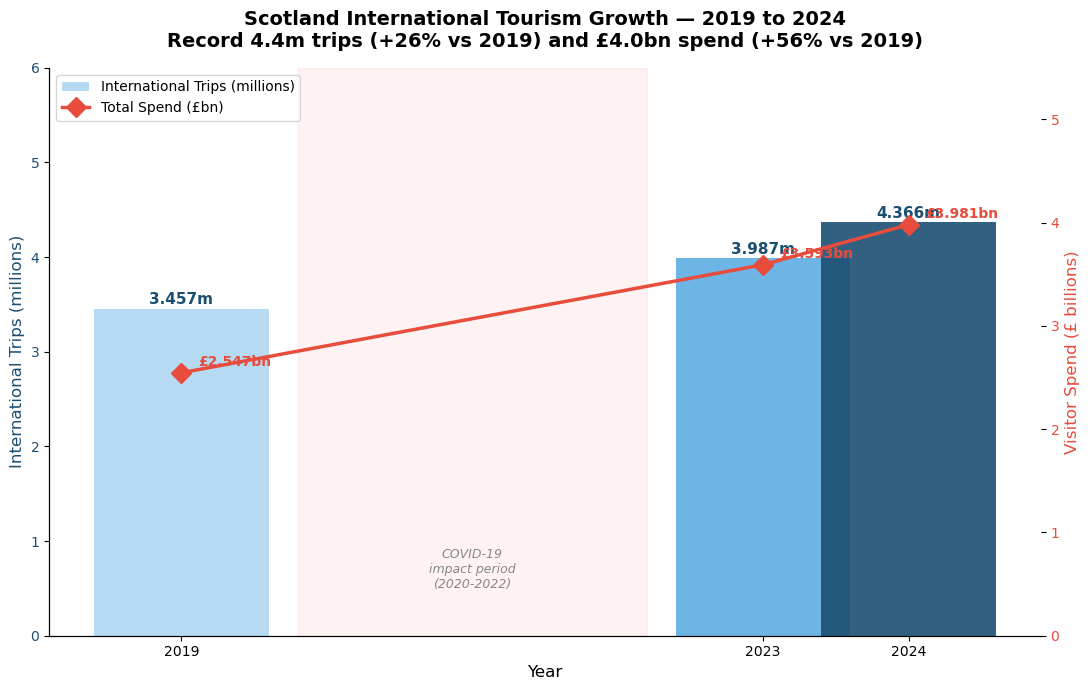

In [38]:
# ============================================================
# FIGURE 8: International Tourism Growth
# Dual axis chart showing:
#   Bars   = International trip volume (millions)
#   Line   = Total spend (£ billions)
# Covers 2019 pre-COVID baseline, 2023 recovery, 2024 record
# ============================================================

fig, ax1 = plt.subplots(figsize=(11, 7))

# Left axis — trip volume bars
bars = ax1.bar(
    ips_annual['Year'],
    ips_annual['Trips_m'],
    width=1.2,
    color=['#AED6F1', '#5DADE2', '#1B4F72'],
    alpha=0.9,
    label='International Trips (millions)'
)

# Value labels on bars
for bar, val in zip(bars, ips_annual['Trips_m']):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f'{val}m',
        ha='center', fontsize=11,
        fontweight='bold', color='#1B4F72'
    )

ax1.set_ylabel('International Trips (millions)', color='#1B4F72', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#1B4F72')
ax1.set_ylim(0, 6)
ax1.set_xticks([2019, 2023, 2024])
ax1.set_xlabel('Year', fontsize=12)

# Right axis — spend line
ax2 = ax1.twinx()

ax2.plot(
    ips_annual['Year'],
    ips_annual['Spend_£bn'],
    color='#E74C3C',
    marker='D',
    linewidth=2.5,
    markersize=10,
    label='Total Spend (£bn)'
)

# Spend value labels
for _, row in ips_annual.iterrows():
    ax2.annotate(
        f'£{row["Spend_£bn"]}bn',
        (row['Year'], row['Spend_£bn']),
        textcoords='offset points',
        xytext=(12, 5),
        fontsize=10,
        color='#E74C3C',
        fontweight='bold'
    )

ax2.set_ylabel('Visitor Spend (£ billions)', color='#E74C3C', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#E74C3C')
ax2.set_ylim(0, 5.5)

# Add COVID gap annotation
ax1.annotate(
    'COVID-19\nimpact period\n(2020-2022)',
    xy=(2021, 0.5),
    fontsize=9,
    color='#888888',
    ha='center',
    style='italic'
)
ax1.axvspan(2019.8, 2022.2, alpha=0.05, color='red')

ax1.set_title(
    'Scotland International Tourism Growth — 2019 to 2024\n'
    'Record 4.4m trips (+26% vs 2019) and £4.0bn spend (+56% vs 2019)',
    fontsize=14, fontweight='bold', pad=15
)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=10)
plt.tight_layout()
plt.savefig('chart8_international_growth.png', dpi=150, bbox_inches='tight')
plt.show()

### Figure 8: Scotland International Tourism Growth (2019–2024)
**Source:** ONS (2024); VisitBritain (2025)

---

**What the chart shows:**
Dual-axis chart showing international trip volume (blue 
bars, left axis) and total international spend (red line, 
right axis) across three key time points: the 2019 
pre-pandemic baseline, the 2023 recovery year and the 
2024 record performance. The shaded area indicates the 
COVID-19 impact period 2020–2022.

**Key finding:**
International visits reached 4.366 million in 2024, a 
26.3% increase on the 2019 baseline. Total international 
expenditure reached £3.981 billion, a 56.3% increase on 
2019. Spend grew at more than double the rate of trip 
volume versus 2019, mirroring the volume-value divergence 
identified in domestic overnight tourism.

**What this means:**
Scotland achieved record international tourism performance 
in 2024 and outperformed all other UK nations and regions 
in both trip and spend growth. The pattern of spend growing 
faster than volume suggests the shift toward higher-value 
visits is a broad structural trend across Scotland's entire 
visitor economy rather than a single-stream phenomenon.

In [39]:
# ============================================================
# Growth calculations vs 2019 pre-COVID baseline
# and vs 2023 for year on year comparison
# ============================================================

trips_vs_2019 = (4.366 - 3.457) / 3.457 * 100
spend_vs_2019 = (3.981 - 2.547) / 2.547 * 100
trips_vs_2023 = (4.366 - 3.987) / 3.987 * 100
spend_vs_2023 = (3.981 - 3.593) / 3.593 * 100
spt_change    = (912   - 901)   / 901   * 100

print("SCOTLAND INTERNATIONAL TOURISM — GROWTH ANALYSIS")
print("=" * 55)
print(f"\nPerformance vs 2019 pre-COVID baseline:")
print(f"  Trips:  3.457m → 4.366m  (+{trips_vs_2019:.1f}%)")
print(f"  Spend:  £2.547bn → £3.981bn  (+{spend_vs_2019:.1f}%)")

print(f"\nPerformance vs 2023:")
print(f"  Trips:  3.987m → 4.366m  (+{trips_vs_2023:.1f}%)")
print(f"  Spend:  £3.593bn → £3.981bn  (+{spend_vs_2023:.1f}%)")
print(f"  Spend per trip: £901 → £912  (+{spt_change:.1f}%)")

print(f"\nScotland vs UK context:")
print(f"  Scotland trips growth vs 2019:  +{trips_vs_2019:.1f}%")
print(f"  Most UK regions still below 2019 levels")
print(f"  Scotland showed strongest growth of all UK nations in 2024")

print(f"\nSpend breakdown 2024:")
print(f"  Total international spend: £3,981 million")
print(f"  Spend per trip: £912")
print(f"  Nights per trip: 7.0 (down from 8.6 in 2023)")
print(f"  Spend per night: £129 (up from £105 in 2023)")
print(f"\nTrend: shorter but higher value visits")

SCOTLAND INTERNATIONAL TOURISM — GROWTH ANALYSIS

Performance vs 2019 pre-COVID baseline:
  Trips:  3.457m → 4.366m  (+26.3%)
  Spend:  £2.547bn → £3.981bn  (+56.3%)

Performance vs 2023:
  Trips:  3.987m → 4.366m  (+9.5%)
  Spend:  £3.593bn → £3.981bn  (+10.8%)
  Spend per trip: £901 → £912  (+1.2%)

Scotland vs UK context:
  Scotland trips growth vs 2019:  +26.3%
  Most UK regions still below 2019 levels
  Scotland showed strongest growth of all UK nations in 2024

Spend breakdown 2024:
  Total international spend: £3,981 million
  Spend per trip: £912
  Nights per trip: 7.0 (down from 8.6 in 2023)
  Spend per night: £129 (up from £105 in 2023)

Trend: shorter but higher value visits


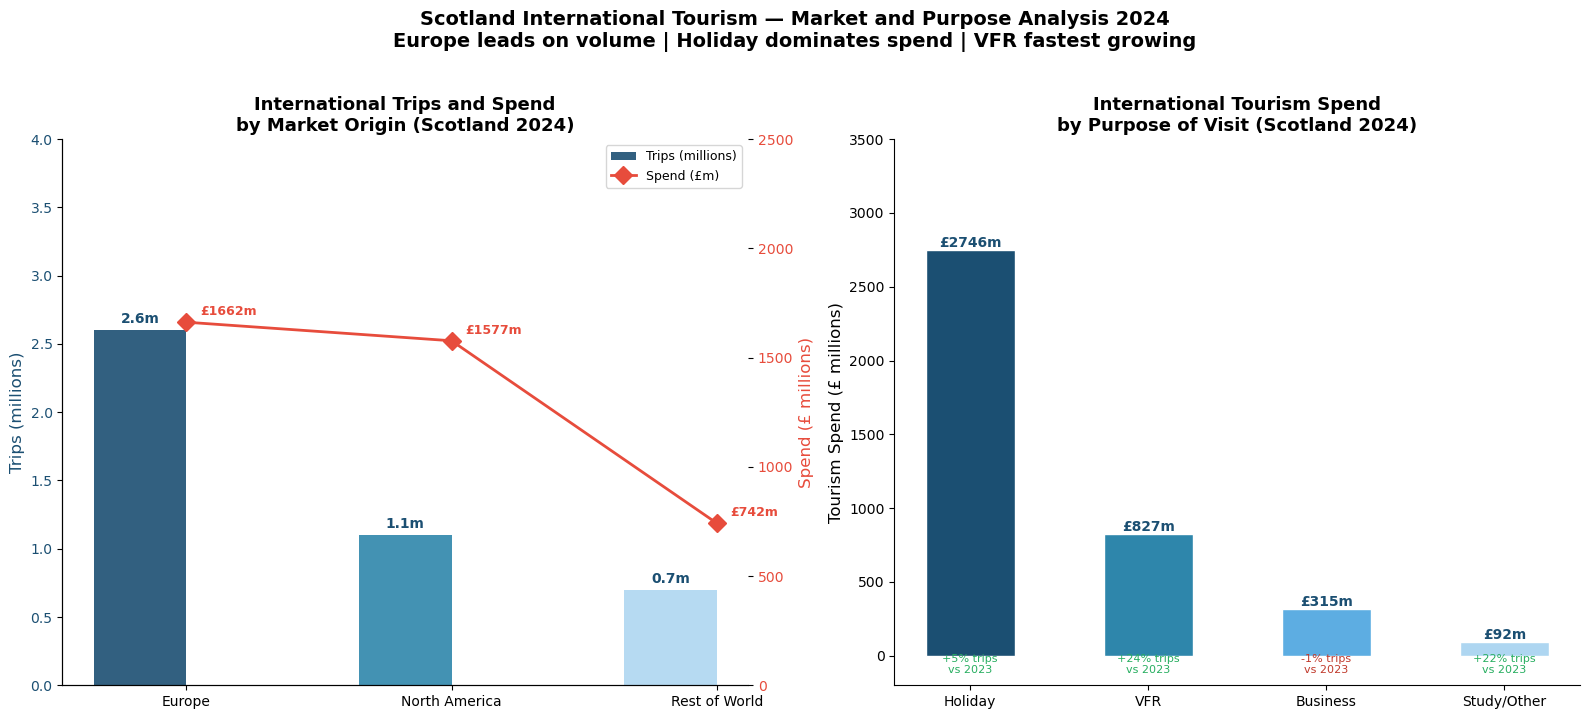

In [40]:
# ============================================================
# FIGURE 9: International Market Breakdown 2024
# Shows two dimensions of international tourism:
#   Left  = Market share by region of origin
#           (Europe, North America, Rest of World)
#   Right = Purpose of visit breakdown
#           (Holiday, VFR, Business, Study/Other)
# Identifies highest value and fastest growing segments
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ---- Left chart: Market origin breakdown ----
colours_market = ['#1B4F72', '#2E86AB', '#AED6F1']

# Grouped bars — trips and spend side by side
x = np.arange(len(ips_market['Market']))
width = 0.35

bars1 = axes[0].bar(
    x - width / 2,
    ips_market['Trips_m'],
    width,
    color=colours_market,
    alpha=0.9,
    label='Trips (millions)'
)
axes[0].set_ylabel('Trips (millions)', color='#1B4F72', fontsize=12)
axes[0].tick_params(axis='y', labelcolor='#1B4F72')
axes[0].set_ylim(0, 4)

# Value labels
for bar, val in zip(bars1, ips_market['Trips_m']):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f'{val}m',
        ha='center', fontsize=10,
        fontweight='bold', color='#1B4F72'
    )

# Second axis for spend
ax0b = axes[0].twinx()
ax0b.plot(
    x,
    ips_market['Spend_£m'],
    color='#E74C3C',
    marker='D',
    linewidth=2,
    markersize=9,
    label='Spend (£m)'
)

for i, row in ips_market.iterrows():
    ax0b.annotate(
        f'£{row["Spend_£m"]}m',
        (i, row['Spend_£m']),
        textcoords='offset points',
        xytext=(10, 5),
        fontsize=9,
        color='#E74C3C',
        fontweight='bold'
    )

ax0b.set_ylabel('Spend (£ millions)', color='#E74C3C', fontsize=12)
ax0b.tick_params(axis='y', labelcolor='#E74C3C')
ax0b.set_ylim(0, 2500)

axes[0].set_xticks(x)
axes[0].set_xticklabels(ips_market['Market'], fontsize=10)
axes[0].set_title('International Trips and Spend\nby Market Origin (Scotland 2024)',
                  fontsize=13, fontweight='bold')

h1, l1 = axes[0].get_legend_handles_labels()
h2, l2 = ax0b.get_legend_handles_labels()
axes[0].legend(h1 + h2, l1 + l2, loc='upper right', fontsize=9)

# ---- Right chart: Purpose of visit ----
colours_purpose = ['#1B4F72', '#2E86AB', '#5DADE2', '#AED6F1']

bars2 = axes[1].bar(
    ips_purpose['Purpose'],
    ips_purpose['Spend_£m'],
    color=colours_purpose,
    edgecolor='white',
    linewidth=1,
    width=0.5
)

for bar, val in zip(bars2, ips_purpose['Spend_£m']):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20,
        f'£{val}m',
        ha='center', fontsize=10,
        fontweight='bold', color='#1B4F72'
    )

# Add growth rate labels below x axis
for i, row in ips_purpose.iterrows():
    axes[1].text(
        i, -120,
        f'{row["Change_vs_2023_trips_pct"]:+d}% trips\nvs 2023',
        ha='center', fontsize=8,
        color='#27AE60' if row['Change_vs_2023_trips_pct'] > 0 else '#C0392B'
    )

axes[1].set_ylabel('Tourism Spend (£ millions)', fontsize=12)
axes[1].set_ylim(-200, 3500)
axes[1].set_title('International Tourism Spend\nby Purpose of Visit (Scotland 2024)',
                  fontsize=13, fontweight='bold')

plt.suptitle(
    'Scotland International Tourism — Market and Purpose Analysis 2024\n'
    'Europe leads on volume | Holiday dominates spend | VFR fastest growing',
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig('chart9_international_markets.png', dpi=150, bbox_inches='tight')
plt.show()

### Figure 9: Scotland International Tourism Market and Purpose Analysis (2024)
**Source:** ONS (2024); VisitBritain (2025)

---

**What the chart shows:**
Two-panel chart showing international tourism broken down 
by market of origin (left panel: grouped bars for trips 
and line for spend) and purpose of visit (right panel:
bar chart with growth rate labels).

**Key finding:**
North American visitors generated £1,577 million (40% of 
total spend) from only 25% of trip volume: an average 
spend of £1,434 per trip versus £639 for European visitors. 
VFR (Visiting Friends and Relatives) was the fastest 
growing purpose segment at +24% versus 2023.

**What this means:**
North American visitors represent Scotland's highest-value 
international segment by a margin of £795 per trip over 
European visitors, making them the priority target for 
international marketing investment. The rapid growth of 
VFR tourism highlights Scotland's diaspora connections 
as a distinctive competitive advantage directly addressed 
in Recommendation 3.

In [41]:
# ============================================================
# Market and purpose analysis
# Identifies highest value and fastest growing segments
# ============================================================

print("INTERNATIONAL MARKET ANALYSIS — SCOTLAND 2024")
print("=" * 55)

print("\nBy region of origin:")
for _, row in ips_market.iterrows():
    spend_per_trip = (row['Spend_£m'] * 1_000_000) / (row['Trips_m'] * 1_000_000)
    spend_per_night = (row['Spend_£m'] * 1_000_000) / (row['Nights_m'] * 1_000_000)
    trips_pct = row['Trips_m'] / ips_market['Trips_m'].sum() * 100
    spend_pct = row['Spend_£m'] / ips_market['Spend_£m'].sum() * 100
    print(f"\n  {row['Market']}:")
    print(f"    Trips:          {row['Trips_m']}m ({trips_pct:.0f}% of total)")
    print(f"    Spend:          £{row['Spend_£m']}m ({spend_pct:.0f}% of total)")
    print(f"    Spend per trip: £{spend_per_trip:.0f}")
    print(f"    Spend per night:£{spend_per_night:.0f}")
    print(f"    Trip growth vs 2023: {row['Change_vs_2023_trips_pct']:+d}%")

print("\nBy purpose of visit:")
for _, row in ips_purpose.iterrows():
    spend_pct = row['Spend_£m'] / ips_purpose['Spend_£m'].sum() * 100
    trips_pct = row['Trips_m'] / ips_purpose['Trips_m'].sum() * 100
    print(f"\n  {row['Purpose']}:")
    print(f"    Trips:  {row['Trips_m']}m ({trips_pct:.0f}% of total)")
    print(f"    Spend:  £{row['Spend_£m']}m ({spend_pct:.0f}% of total)")
    print(f"    Trip growth vs 2023: {row['Change_vs_2023_trips_pct']:+d}%")

print(f"\nKey strategic insight:")
print(f"  North America = {1577/1662*100:.0f}% of Europe spend")
print(f"  but only {1.1/2.6*100:.0f}% of Europe trip volume")
print(f"  → North American visitors spend significantly more per trip")
na_spt = (1577 * 1_000_000) / (1.1 * 1_000_000)
eu_spt = (1662 * 1_000_000) / (2.6 * 1_000_000)
print(f"  North America spend per trip: £{na_spt:.0f}")
print(f"  Europe spend per trip:        £{eu_spt:.0f}")
print(f"  North America premium:        £{na_spt - eu_spt:.0f} more per trip")

INTERNATIONAL MARKET ANALYSIS — SCOTLAND 2024

By region of origin:

  Europe:
    Trips:          2.6m (59% of total)
    Spend:          £1662m (42% of total)
    Spend per trip: £639
    Spend per night:£111
    Trip growth vs 2023: +11%

  North America:
    Trips:          1.1m (25% of total)
    Spend:          £1577m (40% of total)
    Spend per trip: £1434
    Spend per night:£188
    Trip growth vs 2023: +15%

  Rest of World:
    Trips:          0.7m (16% of total)
    Spend:          £742m (19% of total)
    Spend per trip: £1060
    Spend per night:£102
    Trip growth vs 2023: -1%

By purpose of visit:

  Holiday:
    Trips:  2.6m (59% of total)
    Spend:  £2746m (69% of total)
    Trip growth vs 2023: +5%

  VFR:
    Trips:  1.3m (30% of total)
    Spend:  £827m (21% of total)
    Trip growth vs 2023: +24%

  Business:
    Trips:  0.4m (9% of total)
    Spend:  £315m (8% of total)
    Trip growth vs 2023: -1%

  Study/Other:
    Trips:  0.1m (2% of total)
    Spend:  £92

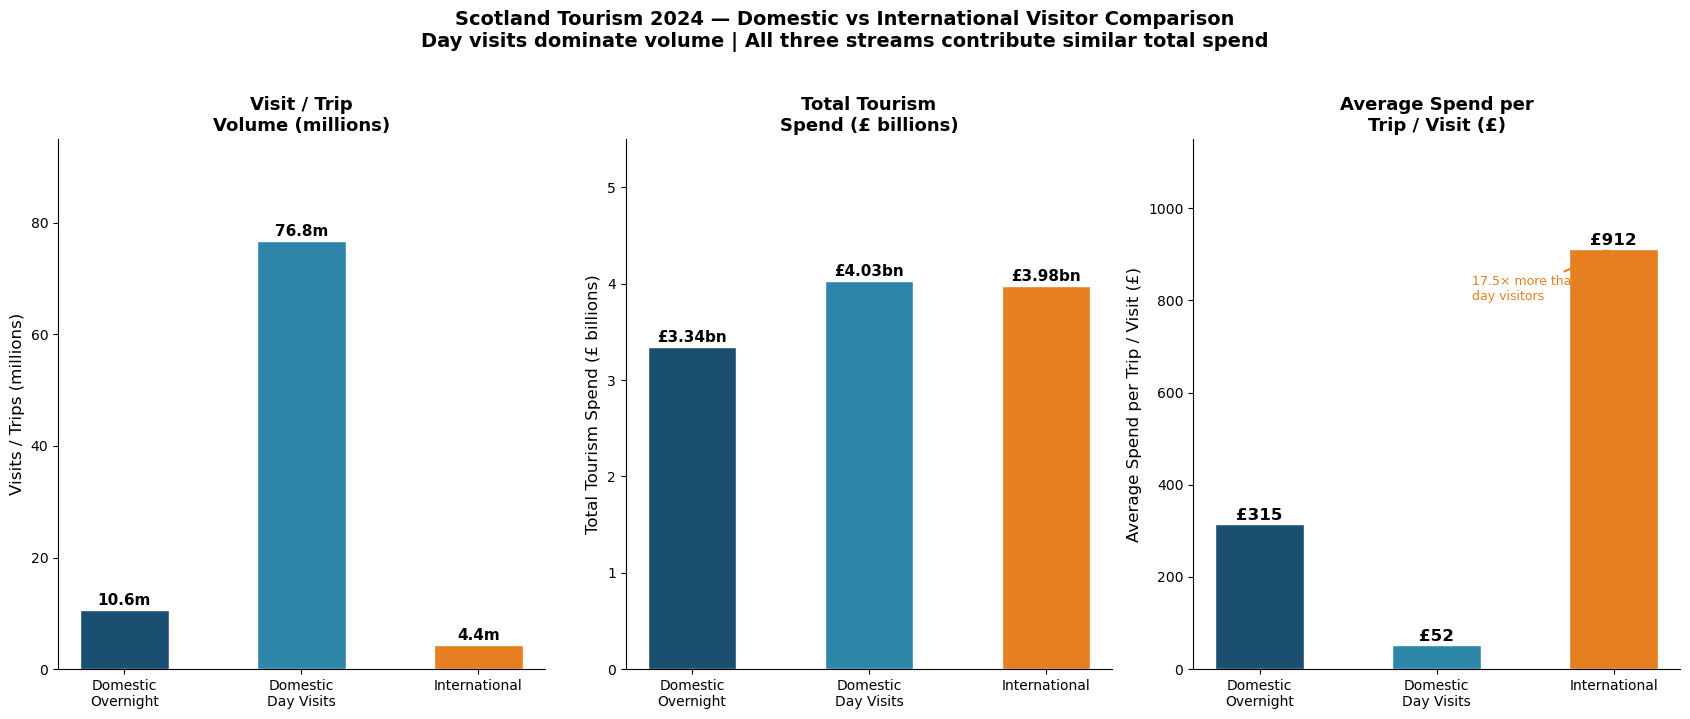

In [42]:
# ============================================================
# FIGURE 10 — Domestic vs International Comparison
# Brings together all three visitor types from Datasets 1-3:
#   1. Domestic Overnight (GBTS)
#   2. Domestic Day Visits (GBTS)
#   3. International (IPS)
# Compares volume, total spend and spend per trip/visit
# ============================================================

# Combined visitor comparison dataframe
visitor_comparison = pd.DataFrame({
    'Visitor_Type'      : ['Domestic\nOvernight', 'Domestic\nDay Visits', 'International'],
    'Visits_m'          : [10.6,                   76.8,                   4.4],
    'Spend_£bn'         : [3.34,                   4.03,                   3.98],
    'Avg_Spend'         : [315,                    52,                     912]
})

colours3 = ['#1B4F72', '#2E86AB', '#E67E22']

fig, axes = plt.subplots(1, 3, figsize=(17, 7))

# ---- Panel 1: Visit / Trip Volume ----
bars1 = axes[0].bar(
    visitor_comparison['Visitor_Type'],
    visitor_comparison['Visits_m'],
    color=colours3,
    edgecolor='white',
    linewidth=1,
    width=0.5
)
for bar, val in zip(bars1, visitor_comparison['Visits_m']):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f'{val}m',
        ha='center', fontsize=11,
        fontweight='bold'
    )
axes[0].set_ylabel('Visits / Trips (millions)', fontsize=12)
axes[0].set_ylim(0, 95)
axes[0].set_title('Visit / Trip\nVolume (millions)',
                  fontsize=13, fontweight='bold')

# ---- Panel 2: Total Spend ----
bars2 = axes[1].bar(
    visitor_comparison['Visitor_Type'],
    visitor_comparison['Spend_£bn'],
    color=colours3,
    edgecolor='white',
    linewidth=1,
    width=0.5
)
for bar, val in zip(bars2, visitor_comparison['Spend_£bn']):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f'£{val}bn',
        ha='center', fontsize=11,
        fontweight='bold'
    )
axes[1].set_ylabel('Total Tourism Spend (£ billions)', fontsize=12)
axes[1].set_ylim(0, 5.5)
axes[1].set_title('Total Tourism\nSpend (£ billions)',
                  fontsize=13, fontweight='bold')

# ---- Panel 3: Average Spend per Trip/Visit ----
bars3 = axes[2].bar(
    visitor_comparison['Visitor_Type'],
    visitor_comparison['Avg_Spend'],
    color=colours3,
    edgecolor='white',
    linewidth=1,
    width=0.5
)
for bar, val in zip(bars3, visitor_comparison['Avg_Spend']):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 8,
        f'£{val}',
        ha='center', fontsize=12,
        fontweight='bold'
    )

# Add annotation highlighting the international premium
axes[2].annotate(
    '17.5× more than\nday visitors',
    xy=(2, 912),
    xytext=(1.2, 800),
    fontsize=9,
    color='#E67E22',
    arrowprops=dict(arrowstyle='->', color='#E67E22', lw=1.5)
)

axes[2].set_ylabel('Average Spend per Trip / Visit (£)', fontsize=12)
axes[2].set_ylim(0, 1150)
axes[2].set_title('Average Spend per\nTrip / Visit (£)',
                  fontsize=13, fontweight='bold')

plt.suptitle(
    'Scotland Tourism 2024 — Domestic vs International Visitor Comparison\n'
    'Day visits dominate volume | All three streams contribute similar total spend',
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig('chart10_domestic_vs_international.png', dpi=150, bbox_inches='tight')
plt.show()

### Figure 10: Scotland Tourism — Domestic vs International Visitor Comparison (2024)
**Source:** VisitScotland (2024a; 2024b); ONS (2024)

---

**What the chart shows:**
Three-panel comparison chart showing domestic overnight, 
domestic day visit and international visitor segments 
across three dimensions: trip/visit volume (left), 
total tourism spend (centre) and average spend per 
trip/visit (right).

**Key finding:**
Despite domestic day visits being 17.5 times more numerous 
than international trips (76.8 million vs 4.4 million), all 
three streams generate similar total spend between £3.34 
billion and £4.03 billion each. International visitors 
spend £912 per trip versus £315 domestic overnight and 
£52 day visits. The combined total of £11.35 billion 
closely matches VisitScotland's reported £11.4 billion — 
providing cross-validation of the four-dataset approach.

**What this means:**
Growing international tourism by one million trips generates 
approximately £912 million in additional spend — 17 times 
more than the equivalent growth in day visits. This 
confirms international tourism as the highest economic 
return growth opportunity and supports the visitor yield 
framework proposed in Recommendation 4.

In [43]:
# ============================================================
# Cross-visitor type analysis
# Identifies the economic efficiency of each visitor segment
# ============================================================

print("DOMESTIC vs INTERNATIONAL VISITOR COMPARISON — 2024")
print("=" * 60)

for _, row in visitor_comparison.iterrows():
    print(f"\n{row['Visitor_Type'].replace(chr(10), ' ')}:")
    print(f"  Volume:           {row['Visits_m']}m trips/visits")
    print(f"  Total spend:      £{row['Spend_£bn']}bn")
    print(f"  Avg spend:        £{row['Avg_Spend']} per trip/visit")
    spend_per_bn_visits = row['Spend_£bn'] / row['Visits_m']
    print(f"  Spend efficiency: £{spend_per_bn_visits:.3f}bn per million visits")

print(f"\nKEY COMPARISONS")
print("=" * 60)

# Volume comparisons
dv_vol   = 76.8
on_vol   = 10.6
int_vol  = 4.4

# Spend comparisons
dv_spend  = 3.34
on_spend  = 4.03
int_spend = 3.98

# Average spend comparisons
dv_avg  = 52
on_avg  = 315
int_avg = 912

print(f"\nVolume:")
print(f"  Day visits are {dv_vol/int_vol:.1f}x more numerous than international trips")
print(f"  Day visits are {dv_vol/on_vol:.1f}x more numerous than overnight trips")

print(f"\nTotal spend:")
print(f"  All three streams generate remarkably similar total spend")
print(f"  Day visits:  £{on_spend}bn")
print(f"  Overnight:   £{dv_spend}bn")
print(f"  International: £{int_spend}bn")
total = on_spend + dv_spend + int_spend
print(f"  Combined total: £{total:.2f}bn")

print(f"\nAverage spend per trip/visit:")
print(f"  International visitors spend {int_avg/on_avg:.1f}x more than domestic overnight")
print(f"  International visitors spend {int_avg/dv_avg:.1f}x more than day visitors")
print(f"  Domestic overnight spend {on_avg/dv_avg:.1f}x more than day visitors")

print(f"\nStrategic implication:")
print(f"  Growing international visits by 1 million = £{int_avg}m additional spend")
print(f"  Growing overnight visits by 1 million = £{on_avg}m additional spend")
print(f"  Growing day visits by 1 million = £{dv_avg}m additional spend")
print(f"  → International tourism delivers {int_avg//dv_avg}x more spend per additional visitor")
print(f"    than day visits and {int_avg//on_avg}x more than domestic overnight")

DOMESTIC vs INTERNATIONAL VISITOR COMPARISON — 2024

Domestic Overnight:
  Volume:           10.6m trips/visits
  Total spend:      £3.34bn
  Avg spend:        £315 per trip/visit
  Spend efficiency: £0.315bn per million visits

Domestic Day Visits:
  Volume:           76.8m trips/visits
  Total spend:      £4.03bn
  Avg spend:        £52 per trip/visit
  Spend efficiency: £0.052bn per million visits

International:
  Volume:           4.4m trips/visits
  Total spend:      £3.98bn
  Avg spend:        £912 per trip/visit
  Spend efficiency: £0.905bn per million visits

KEY COMPARISONS

Volume:
  Day visits are 17.5x more numerous than international trips
  Day visits are 7.2x more numerous than overnight trips

Total spend:
  All three streams generate remarkably similar total spend
  Day visits:  £4.03bn
  Overnight:   £3.34bn
  International: £3.98bn
  Combined total: £11.35bn

Average spend per trip/visit:
  International visitors spend 2.9x more than domestic overnight
  Internation

---
## Section 8: Machine Learning Analysis

This section applies two machine learning techniques to 
Scotland's regional tourism data to identify structural 
patterns and build a predictive model of tourism 
expenditure. Both methods use Dataset 4: Regional 
Domestic Tourism from statistics.gov.scot.

---

### 8.1 K-Means Clustering

**Algorithm:** K-Means - unsupervised machine learning
**Library:** scikit-learn KMeans
**Data:** All 32 Scottish council areas, most recent 
period (2017–2019)
**Features used:**

| Feature | Description | Unit |
|---------|-------------|------|
| Visits_m | Tourism visit volume | Thousand visits |
| Spend_£m | Tourism expenditure | £ Millions |
| Nights_m | Nights stayed | Thousand nights |
| Spend_per_Visit | Derived: spend ÷ visits × 1000 | £ per visit |
| Nights_per_Visit | Derived: nights ÷ visits | Nights per visit |

**Why standardisation is required:**
Features are measured on very different scales, for 
example visits range from 7 to 2,607 thousand while 
nights per visit ranges from approximately 0.5 to 6.6. 
Without standardisation larger-scale features would 
dominate the distance calculations unfairly. 
StandardScaler is applied to transform all features to 
mean = 0 and standard deviation = 1 before clustering.

**How K is selected:**
The elbow method is used to identify the optimal number 
of clusters. Inertia, the sum of squared distances from 
each point to its cluster centroid, is calculated for 
K = 2 to K = 8. The optimal K is identified at the point 
where the rate of inertia reduction slows most sharply.

Two visualisations are produced:

- **Figure 11:** Elbow method — optimal cluster selection
- **Figure 12:** K-Means cluster scatter plot — regional 
  tourism profiles

---

### 8.2 Linear Regression

**Algorithm:** Simple linear regression - supervised 
statistical modelling
**Library:** scikit-learn LinearRegression
**Data:** All 32 council areas × 9 time periods = 
288 data points
**Variables:**

| Variable | Role | Description |
|----------|------|-------------|
| Visits_m | Independent (X) | Tourism visit volume |
| Spend_£m | Dependent (Y) | Tourism expenditure |

**Performance metrics used:**
- **R²**: proportion of spend variation explained by 
  visit volume
- **RMSE**: root mean squared error (average prediction 
  error in £ millions)
- **MAE**: mean absolute error (average absolute 
  prediction error in £ millions)

**Why this model is appropriate:**
The strong visual linear relationship between visits and 
spend observed in the bubble chart (Figure 3) justifies 
the application of linear regression. The model is 
intentionally kept simple, one independent variable 
to produce an interpretable and directly actionable 
result for VisitScotland's planning purposes.

One visualisation is produced:

- **Figure 13:** Linear regression - tourism spend 
  predicted from visit volume

---

### Relationship to Previous Sections

The machine learning analysis in this section builds 
directly on the exploratory regional analysis in 
Section 4. The three clusters identified by K-Means 
correspond to the three destination tiers observed 
visually in Figure 3, while the regression model 
quantifies the visit-spend relationship whose strength 
was first indicated by the bubble chart pattern. Together 
these two methods move the analysis from description 
to formal statistical classification and prediction.

In [44]:
# ============================================================
# K-MEANS CLUSTERING
# Groups Scottish council areas into distinct tourism profiles
# based on multiple characteristics simultaneously
#
# Features used:
#   - Visit volume (thousand visits)
#   - Tourism spend (£ millions)
#   - Nights stayed (thousand nights)
#   - Spend per visit (£)
#   - Nights per visit
#
# Algorithm: K-Means - unsupervised machine learning
# that partitions regions into K groups where each region
# belongs to the cluster with the nearest mean value
# ============================================================

# Build feature matrix from Dataset 4 latest period
pivot = df_reg_gb[df_reg_gb['DateCode'] == latest_period].pivot_table(
    index='Region',
    columns='Measure',
    values='Value'
).reset_index()
pivot.columns.name = None

# Rename columns
pivot = pivot.rename(columns={
    'Expenditure' : 'Spend_£m',
    'Nights'      : 'Nights_m',
    'Visits'      : 'Visits_m'
}).dropna()

# Feature engineering — derived metrics
pivot['Spend_per_Visit']  = (pivot['Spend_£m'] / pivot['Visits_m']) * 1000
pivot['Nights_per_Visit'] = pivot['Nights_m']  / pivot['Visits_m']

print("CLUSTERING FEATURE MATRIX")
print("=" * 55)
print(f"Regions included: {len(pivot)}")
print(f"\nFeatures used for clustering:")
features = ['Visits_m', 'Spend_£m', 'Nights_m',
            'Spend_per_Visit', 'Nights_per_Visit']
for f in features:
    print(f"  - {f}")

print(f"\nFeature summary statistics:")
display(pivot[features].describe().round(2))

CLUSTERING FEATURE MATRIX
Regions included: 32

Features used for clustering:
  - Visits_m
  - Spend_£m
  - Nights_m
  - Spend_per_Visit
  - Nights_per_Visit

Feature summary statistics:


,Visits_m,Spend_£m,Nights_m,Spend_per_Visit,Nights_per_Visit
count,32.00,32.00,32.00,32.00,32.00
mean,403.84,92.78,1294.69,198.76,3.41
std,595.22,157.31,1834.28,64.11,1.28
min,7.00,1.00,14.00,78.95,1.56
25%,69.50,14.25,221.75,167.17,2.65
50%,146.00,36.00,586.00,200.28,3.26
75%,423.00,89.25,1506.25,226.27,3.54
max,2607.00,728.00,7944.00,413.04,8.10


In [45]:
# ============================================================
# Standardise features using StandardScaler
# Required because features have very different scales
# e.g. Visits range 7-2607 vs Nights_per_Visit range 0.5-3.5
# StandardScaler transforms each feature to mean=0, std=1
# ensuring no single feature dominates the clustering
# ============================================================

scaler  = StandardScaler()
X_scaled = scaler.fit_transform(pivot[features].values)

print("✅ Features standardised")
print(f"Shape of scaled matrix: {X_scaled.shape}")
print(f"\nBefore scaling — Visits range: {pivot['Visits_m'].min():.0f} to {pivot['Visits_m'].max():.0f}")
print(f"After scaling  — Visits range: {X_scaled[:,0].min():.2f} to {X_scaled[:,0].max():.2f}")
print(f"\nAll features now on same scale — mean=0, std=1")

✅ Features standardised
Shape of scaled matrix: (32, 5)

Before scaling — Visits range: 7 to 2607
After scaling  — Visits range: -0.68 to 3.76

All features now on same scale — mean=0, std=1


  File "C:\Users\USER\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\USER\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\USER\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\USER\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


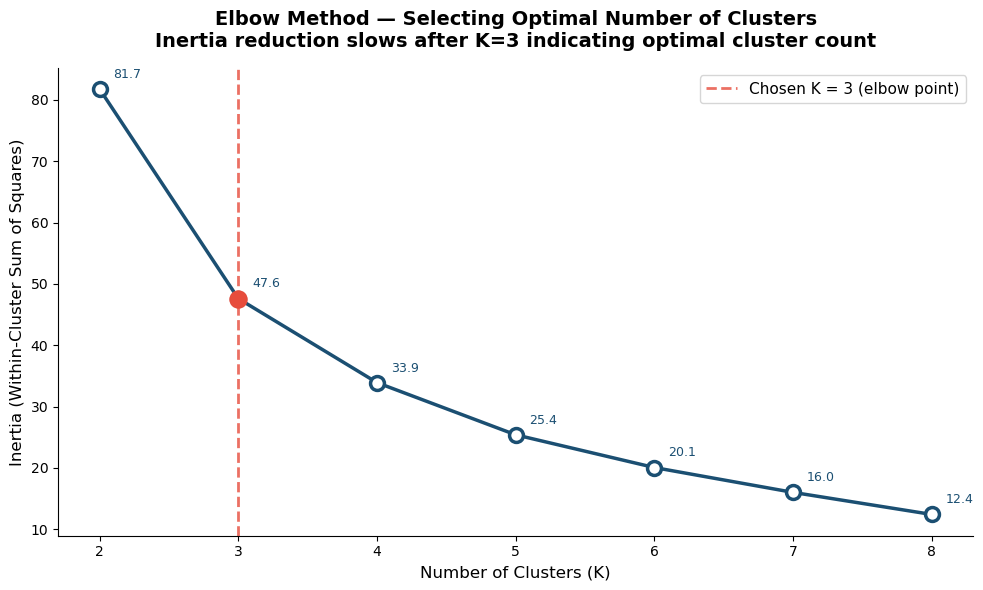

Inertia values by K:
  K=2: 81.75
  K=3: 47.60  (reduction: 34.2)
  K=4: 33.90  (reduction: 13.7)
  K=5: 25.39  (reduction: 8.5)
  K=6: 20.05  (reduction: 5.3)
  K=7: 16.01  (reduction: 4.0)
  K=8: 12.41  (reduction: 3.6)

Largest reduction: K=2→3
Reduction slows significantly after K=3 → optimal K=3


In [46]:
# ============================================================
# FIGURE 11: Elbow Method
# Determines the optimal number of clusters (K)
# Plots inertia (within-cluster variance) for K = 2 to 8
# The elbow point where reduction slows sharply is K=3
# ============================================================

inertias = []
K_range  = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    K_range, inertias,
    marker='o', color='#1B4F72',
    linewidth=2.5, markersize=10,
    markerfacecolor='white',
    markeredgewidth=2.5
)

# Highlight chosen K
ax.axvline(
    x=3, color='#E74C3C',
    linestyle='--', linewidth=2,
    alpha=0.8, label='Chosen K = 3 (elbow point)'
)
ax.scatter([3], [inertias[1]], color='#E74C3C', s=150, zorder=5)

# Annotate inertia values
for k, inertia in zip(K_range, inertias):
    ax.annotate(
        f'{inertia:.1f}',
        (k, inertia),
        textcoords='offset points',
        xytext=(10, 8),
        fontsize=9,
        color='#1B4F72'
    )

ax.set_xlabel('Number of Clusters (K)', fontsize=12)
ax.set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
ax.set_title(
    'Elbow Method — Selecting Optimal Number of Clusters\n'
    'Inertia reduction slows after K=3 indicating optimal cluster count',
    fontsize=14, fontweight='bold', pad=15
)
ax.set_xticks(list(K_range))
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('chart11_elbow.png', dpi=150, bbox_inches='tight')
plt.show()

print("Inertia values by K:")
for k, inertia in zip(K_range, inertias):
    reduction = "" if k == 2 else f"  (reduction: {inertias[list(K_range).index(k)-1] - inertia:.1f})"
    print(f"  K={k}: {inertia:.2f}{reduction}")
print(f"\nLargest reduction: K=2→3")
print(f"Reduction slows significantly after K=3 → optimal K=3")

### Figure 11: Elbow Method - Optimal Cluster Selection for K-Means Analysis
**Source:** Scottish Government (2024) - Regional Domestic Tourism

---

**What the chart shows:**
Line chart plotting within-cluster inertia (the sum of 
squared distances from each data point to its cluster 
centroid) against increasing values of K (number of 
clusters) from K=2 to K=8. The red dashed line marks 
the chosen K=3.

**Key finding:**
Within-cluster inertia declined sharply from 81.7 at K=2 
to 47.6 at K=3 - a reduction of 34.1 points. Subsequent 
reductions were progressively smaller (13.7 to K=4, 8.5 
to K=5) confirming K=3 as the elbow point.

**What this means:**
K=3 is the optimal number of clusters - dividing Scotland's 
32 council areas into three groups captures the most 
meaningful variation in their tourism profiles. Each 
additional cluster beyond three adds relatively little 
explanatory power. This provides statistical justification 
for the three-cluster solution applied in Figure 12.

In [47]:
# ============================================================
# Apply K-Means with K=3, the optimal cluster count
# random_state=42 ensures reproducibility
# n_init=10 runs algorithm 10 times with different seeds
# and selects the best result
# ============================================================

km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
pivot['Cluster'] = km_final.fit_predict(X_scaled)

# Calculate cluster profile means
cluster_means = pivot.groupby('Cluster')[features].mean()

print("CLUSTER PROFILE MEANS")
print("=" * 55)
display(cluster_means.round(2))

# Assign meaningful labels based on cluster characteristics
label_map = {}
for c in range(3):
    row = cluster_means.loc[c]
    if row['Visits_m'] == cluster_means['Visits_m'].max():
        label_map[c] = 'High Volume Hub'
    elif row['Spend_per_Visit'] == cluster_means['Spend_per_Visit'].max():
        label_map[c] = 'High Value Destination'
    else:
        label_map[c] = 'Emerging / Undervisited'

pivot['Cluster_Label'] = pivot['Cluster'].map(label_map)

print("\nCluster label assignments:")
for c, label in label_map.items():
    regions = pivot[pivot['Cluster'] == c]['Region'].tolist()
    print(f"\n  {label}:")
    for r in regions:
        print(f"    - {r}")

CLUSTER PROFILE MEANS


,Visits_m,Spend_£m,Nights_m,Spend_per_Visit,Nights_per_Visit
Cluster,,,,,
0,248.65,49.15,816.04,178.87,3.09
1,108.00,35.67,665.33,315.77,6.64
2,2044.67,528.00,6072.33,254.12,2.97



Cluster label assignments:

  Emerging / Undervisited:
    - Aberdeen City
    - Aberdeenshire
    - Angus
    - Argyll and Bute
    - Clackmannanshire
    - Dumfries and Galloway
    - Dundee City
    - East Ayrshire
    - East Dunbartonshire
    - East Lothian
    - East Renfrewshire
    - Falkirk
    - Fife
    - Inverclyde
    - Midlothian
    - Moray
    - North Ayrshire
    - North Lanarkshire
    - Perth and Kinross
    - Renfrewshire
    - Scottish Borders
    - South Ayrshire
    - South Lanarkshire
    - Stirling
    - West Dunbartonshire
    - West Lothian

  High Value Destination:
    - Na h-Eileanan Siar
    - Orkney Islands
    - Shetland Islands

  High Volume Hub:
    - City of Edinburgh
    - Glasgow City
    - Highland


In [48]:
# ============================================================
# Cluster profile summary: average characteristics
# of each cluster for interpretation and reporting
# ============================================================

print("CLUSTER PROFILE SUMMARY")
print("=" * 60)

cluster_summary = pivot.groupby('Cluster_Label').agg(
    Count           = ('Region', 'count'),
    Avg_Visits      = ('Visits_m', 'mean'),
    Avg_Spend       = ('Spend_£m', 'mean'),
    Avg_Nights      = ('Nights_m', 'mean'),
    Avg_SpendVisit  = ('Spend_per_Visit', 'mean'),
    Avg_NightsVisit = ('Nights_per_Visit', 'mean')
).round(2)

display(cluster_summary)

print("\nRegions in each cluster:")
for label in pivot['Cluster_Label'].unique():
    regions = sorted(pivot[pivot['Cluster_Label'] == label]['Region'].tolist())
    count   = len(regions)
    print(f"\n  {label} ({count} regions):")
    for r in regions:
        print(f"    - {r}")

CLUSTER PROFILE SUMMARY


,Count,Avg_Visits,Avg_Spend,Avg_Nights,Avg_SpendVisit,Avg_NightsVisit
Cluster_Label,,,,,,
Emerging / Undervisited,26,248.65,49.15,816.04,178.87,3.09
High Value Destination,3,108.00,35.67,665.33,315.77,6.64
High Volume Hub,3,2044.67,528.00,6072.33,254.12,2.97



Regions in each cluster:

  Emerging / Undervisited (26 regions):
    - Aberdeen City
    - Aberdeenshire
    - Angus
    - Argyll and Bute
    - Clackmannanshire
    - Dumfries and Galloway
    - Dundee City
    - East Ayrshire
    - East Dunbartonshire
    - East Lothian
    - East Renfrewshire
    - Falkirk
    - Fife
    - Inverclyde
    - Midlothian
    - Moray
    - North Ayrshire
    - North Lanarkshire
    - Perth and Kinross
    - Renfrewshire
    - Scottish Borders
    - South Ayrshire
    - South Lanarkshire
    - Stirling
    - West Dunbartonshire
    - West Lothian

  High Volume Hub (3 regions):
    - City of Edinburgh
    - Glasgow City
    - Highland

  High Value Destination (3 regions):
    - Na h-Eileanan Siar
    - Orkney Islands
    - Shetland Islands


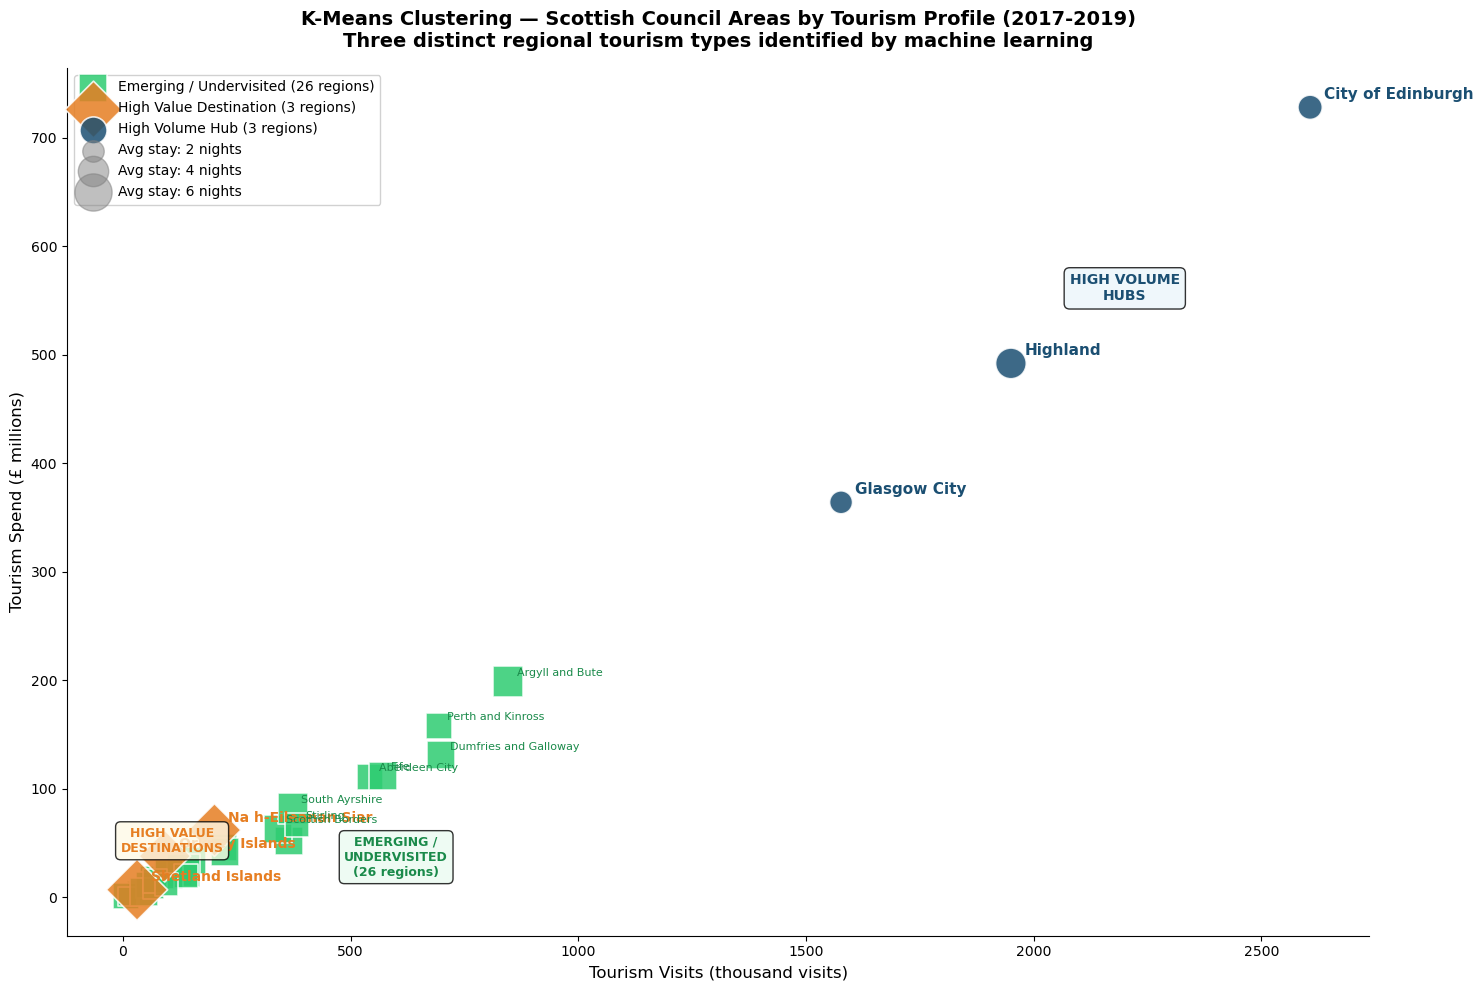

In [49]:
# ============================================================
# FIGURE 12: K-Means Cluster Scatter Plot
# Visualises the three discovered clusters spatially
# showing how regions group by tourism profile
#   X-axis  = Visit volume (thousand visits)
#   Y-axis  = Tourism spend (£ millions)
#   Bubble  = Nights per visit
#   Colour  = Cluster type
# ============================================================

cluster_colours = {
    'High Volume Hub'        : '#1B4F72',
    'High Value Destination' : '#E67E22',
    'Emerging / Undervisited': '#2ECC71'
}

cluster_markers = {
    'High Volume Hub'        : 'o',
    'High Value Destination' : 'D',
    'Emerging / Undervisited': 's'
}

fig, ax = plt.subplots(figsize=(15, 10))

for label, group in pivot.groupby('Cluster_Label'):
    ax.scatter(
        group['Visits_m'],
        group['Spend_£m'],
        s=group['Nights_per_Visit'] * 120,
        color=cluster_colours[label],
        marker=cluster_markers[label],
        alpha=0.85,
        label=f'{label} ({len(group)} regions)',
        edgecolors='white',
        linewidths=1.2,
        zorder=3
    )

# Label High Volume Hubs directly — large and important
for _, row in pivot[pivot['Cluster_Label'] == 'High Volume Hub'].iterrows():
    ax.annotate(
        row['Region'],
        (row['Visits_m'], row['Spend_£m']),
        textcoords='offset points',
        xytext=(10, 6),
        fontsize=11,
        fontweight='bold',
        color='#1B4F72'
    )

# Label High Value Destinations — strategically important
for _, row in pivot[pivot['Cluster_Label'] == 'High Value Destination'].iterrows():
    ax.annotate(
        row['Region'],
        (row['Visits_m'], row['Spend_£m']),
        textcoords='offset points',
        xytext=(10, 6),
        fontsize=10,
        fontweight='bold',
        color='#E67E22'
    )

# Label selected Emerging regions with highest spend
emerging_top = pivot[
    pivot['Cluster_Label'] == 'Emerging / Undervisited'
].nlargest(8, 'Spend_£m')

for _, row in emerging_top.iterrows():
    ax.annotate(
        row['Region'],
        (row['Visits_m'], row['Spend_£m']),
        textcoords='offset points',
        xytext=(6, 4),
        fontsize=8,
        color='#1A8A4A'
    )

# Add cluster boundary annotations
ax.text(
    2200, 550,
    'HIGH VOLUME\nHUBS',
    fontsize=10, color='#1B4F72',
    fontweight='bold', ha='center',
    bbox=dict(boxstyle='round,pad=0.4',
              facecolor='#EBF5FB', alpha=0.8)
)

ax.text(
    108, 42,
    'HIGH VALUE\nDESTINATIONS',
    fontsize=9, color='#E67E22',
    fontweight='bold', ha='center',
    bbox=dict(boxstyle='round,pad=0.4',
              facecolor='#FEF9E7', alpha=0.8)
)

ax.text(
    600, 20,
    'EMERGING /\nUNDERVISITED\n(26 regions)',
    fontsize=9, color='#1A8A4A',
    fontweight='bold', ha='center',
    bbox=dict(boxstyle='round,pad=0.4',
              facecolor='#EAFAF1', alpha=0.8)
)

# Add bubble size legend
for size_val, label in [(2, '2 nights'), (4, '4 nights'), (6, '6 nights')]:
    ax.scatter(
        [], [],
        s=size_val * 120,
        color='grey', alpha=0.5,
        label=f'Avg stay: {label}'
    )

ax.set_xlabel('Tourism Visits (thousand visits)', fontsize=12)
ax.set_ylabel('Tourism Spend (£ millions)', fontsize=12)
ax.set_title(
    f'K-Means Clustering — Scottish Council Areas by Tourism Profile ({latest_period})\n'
    'Three distinct regional tourism types identified by machine learning',
    fontsize=14, fontweight='bold', pad=15
)
ax.legend(
    fontsize=10, loc='upper left',
    framealpha=0.9, edgecolor='#CCCCCC'
)
plt.tight_layout()
plt.savefig('chart12_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

### Figure 12: K-Means Clustering of Scottish Council Areas by Tourism Profile (2017–2019)
**Source:** Scottish Government (2024) — Regional Domestic Tourism

---

**What the chart shows:**
Scatter plot showing all 32 Scottish council areas 
positioned by visit volume (x-axis) and tourism spend 
(y-axis). Bubble size represents average nights per visit. 
Colour identifies cluster membership:
- Dark blue circles = High Volume Hubs
- Orange diamonds = High Value Destinations
- Green squares = Emerging and Undervisited

**Key finding:**
Three statistically distinct clusters were identified:
- High Volume Hubs (3 regions): Edinburgh, Glasgow, 
  Highland - avg 2,045 thousand visits, £528m spend
- High Value Destinations (3 regions): Orkney, Shetland, 
  Na h-Eileanan Siar - highest spend per visit (£316) 
  and longest stays (6.64 nights)
- Emerging and Undervisited (26 regions): avg 249 thousand 
  visits, £49m spend representing 81% of all council areas

**What this means:**
Scotland's regional tourism landscape is not a homogeneous 
entity but three fundamentally distinct destination types 
at different stages of the tourism lifecycle. This finding 
directly challenges the assumption of a uniform national 
tourism strategy and supports the differentiated cluster-
specific management framework proposed in Recommendation 5.

In [50]:
# ============================================================
# Strategic implications of clustering results
# Translates analytical findings into actionable insights
# for VisitScotland recommendations
# ============================================================

print("CLUSTERING STRATEGIC IMPLICATIONS")
print("=" * 60)

print("""
CLUSTER 1 — HIGH VOLUME HUBS (3 regions)
Edinburgh | Glasgow | Highland
─────────────────────────────────────────
  Challenge: Overtourism pressure, infrastructure strain
             seasonal congestion in peak months
  Opportunity: Convert volume visitors to higher value
               Extend average length of stay
               Promote shoulder season visits
  VisitScotland strategy: MANAGE and OPTIMISE
  not grow volume further

CLUSTER 2 — HIGH VALUE DESTINATIONS (3 regions)  
Orkney | Shetland | Na h-Eileanan Siar
─────────────────────────────────────────
  Strength: Highest spend per visit (£316)
            Longest average stay (6.6 nights)
            Distinctive, differentiated product
  Challenge: Remote, limited accommodation capacity
             Accessibility and transport barriers
  Opportunity: Premium positioning, niche marketing
               Target high-spending international visitors
  VisitScotland strategy: DEVELOP and POSITION as
  premium sustainable destinations

CLUSTER 3 — EMERGING / UNDERVISITED (26 regions)
All remaining Scottish council areas
─────────────────────────────────────────
  Challenge: Low visit volumes and spend
             Limited tourism infrastructure
             Low awareness among visitors
  Opportunity: Greatest potential for growth
               Dispersal of visitors from crowded hubs
               Rural tourism, authentic experiences
  VisitScotland strategy: INVEST and DEVELOP
  to unlock latent tourism potential
""")

print("CLUSTER COMPARISON TABLE")
print("=" * 60)
display(cluster_summary.round(2))

CLUSTERING STRATEGIC IMPLICATIONS

CLUSTER 1 — HIGH VOLUME HUBS (3 regions)
Edinburgh | Glasgow | Highland
─────────────────────────────────────────
  Challenge: Overtourism pressure, infrastructure strain
             seasonal congestion in peak months
  Opportunity: Convert volume visitors to higher value
               Extend average length of stay
               Promote shoulder season visits
  VisitScotland strategy: MANAGE and OPTIMISE
  not grow volume further

CLUSTER 2 — HIGH VALUE DESTINATIONS (3 regions)  
Orkney | Shetland | Na h-Eileanan Siar
─────────────────────────────────────────
  Strength: Highest spend per visit (£316)
            Longest average stay (6.6 nights)
            Distinctive, differentiated product
  Challenge: Remote, limited accommodation capacity
             Accessibility and transport barriers
  Opportunity: Premium positioning, niche marketing
               Target high-spending international visitors
  VisitScotland strategy: DEVELOP and POSITION

,Count,Avg_Visits,Avg_Spend,Avg_Nights,Avg_SpendVisit,Avg_NightsVisit
Cluster_Label,,,,,,
Emerging / Undervisited,26,248.65,49.15,816.04,178.87,3.09
High Value Destination,3,108.00,35.67,665.33,315.77,6.64
High Volume Hub,3,2044.67,528.00,6072.33,254.12,2.97


## LINEAR REGRESSION (Prepare Regression Data)

In [51]:
# ============================================================
# LINEAR REGRESSION
# Models the relationship between tourism visit volume
# and tourism spend across all Scottish council areas
# and all time periods
#
# Dependent variable (y):   Tourism Spend (£ millions)
# Independent variable (x): Tourism Visits (thousand visits)
#
# Uses all time periods combined to maximise data points
# giving a more robust and generalisable model
# ============================================================

# Merge visits and spend across all time periods
df_reg_model = pd.merge(
    df_visits[['Region', 'DateCode', 'Value']].rename(
        columns={'Value': 'Visits_m'}),
    df_spend[['Region', 'DateCode', 'Value']].rename(
        columns={'Value': 'Spend_£m'}),
    on=['Region', 'DateCode']
).dropna()

print("REGRESSION DATASET")
print("=" * 50)
print(f"Total data points:  {len(df_reg_model)}")
print(f"Regions included:   {df_reg_model['Region'].nunique()}")
print(f"Time periods:       {df_reg_model['DateCode'].nunique()}")
print(f"\nVisit range:  {df_reg_model['Visits_m'].min():.0f} to "
      f"{df_reg_model['Visits_m'].max():.0f} thousand visits")
print(f"Spend range:  £{df_reg_model['Spend_£m'].min():.0f}m to "
      f"£{df_reg_model['Spend_£m'].max():.0f}m")
print(f"\nFirst 5 rows:")
display(df_reg_model.head())

REGRESSION DATASET
Total data points:  288
Regions included:   32
Time periods:       9

Visit range:  0 to 2607 thousand visits
Spend range:  £0m to £752m

First 5 rows:


,Region,DateCode,Visits_m,Spend_£m
0,West Dunbartonshire,2014-2016,64,12
1,West Dunbartonshire,2017-2019,70,15
2,West Dunbartonshire,2016-2018,56,12
3,West Dunbartonshire,2012-2014,67,10
4,West Dunbartonshire,2009-2011,96,19


In [52]:
# ============================================================
# Build linear regression model
# Split data into features (X) and target (y)
# Fit model and calculate performance metrics
# ============================================================

# Define features and target
X_lr = df_reg_model[['Visits_m']].values
y_lr = df_reg_model['Spend_£m'].values

# Fit linear regression model
model = LinearRegression()
model.fit(X_lr, y_lr)

# Generate predictions
y_pred = model.predict(X_lr)

# Calculate performance metrics
r2   = r2_score(y_lr, y_pred)
rmse = np.sqrt(np.mean((y_lr - y_pred) ** 2))
mae  = np.mean(np.abs(y_lr - y_pred))

print("LINEAR REGRESSION MODEL RESULTS")
print("=" * 50)
print(f"\nModel equation:")
print(f"  Spend (£m) = {model.coef_[0]:.4f} × Visits + {model.intercept_:.2f}")
print(f"\nIn plain English:")
print(f"  For every 1,000 additional visits → "
      f"£{model.coef_[0]*1000:.0f}m more spend")
print(f"  Baseline spend (zero visits) = £{model.intercept_:.2f}m")
print(f"\nModel performance metrics:")
print(f"  R² score:  {r2:.4f} — model explains {r2*100:.1f}% of "
      f"spend variation")
print(f"  RMSE:      £{rmse:.2f}m (average prediction error)")
print(f"  MAE:       £{mae:.2f}m (mean absolute error)")
print(f"\nInterpretation:")
if r2 > 0.8:
    print(f"  Strong positive relationship — visit volume is a")
    print(f"  reliable predictor of tourism spend")
elif r2 > 0.6:
    print(f"  Moderate positive relationship — visit volume explains")
    print(f"  much but not all variation in spend")
else:
    print(f"  Moderate relationship — other factors beyond visit")
    print(f"  volume also influence tourism spend significantly")

LINEAR REGRESSION MODEL RESULTS

Model equation:
  Spend (£m) = 0.2569 × Visits + -13.09

In plain English:
  For every 1,000 additional visits → £257m more spend
  Baseline spend (zero visits) = £-13.09m

Model performance metrics:
  R² score:  0.9725 — model explains 97.2% of spend variation
  RMSE:      £23.35m (average prediction error)
  MAE:       £15.53m (mean absolute error)

Interpretation:
  Strong positive relationship — visit volume is a
  reliable predictor of tourism spend


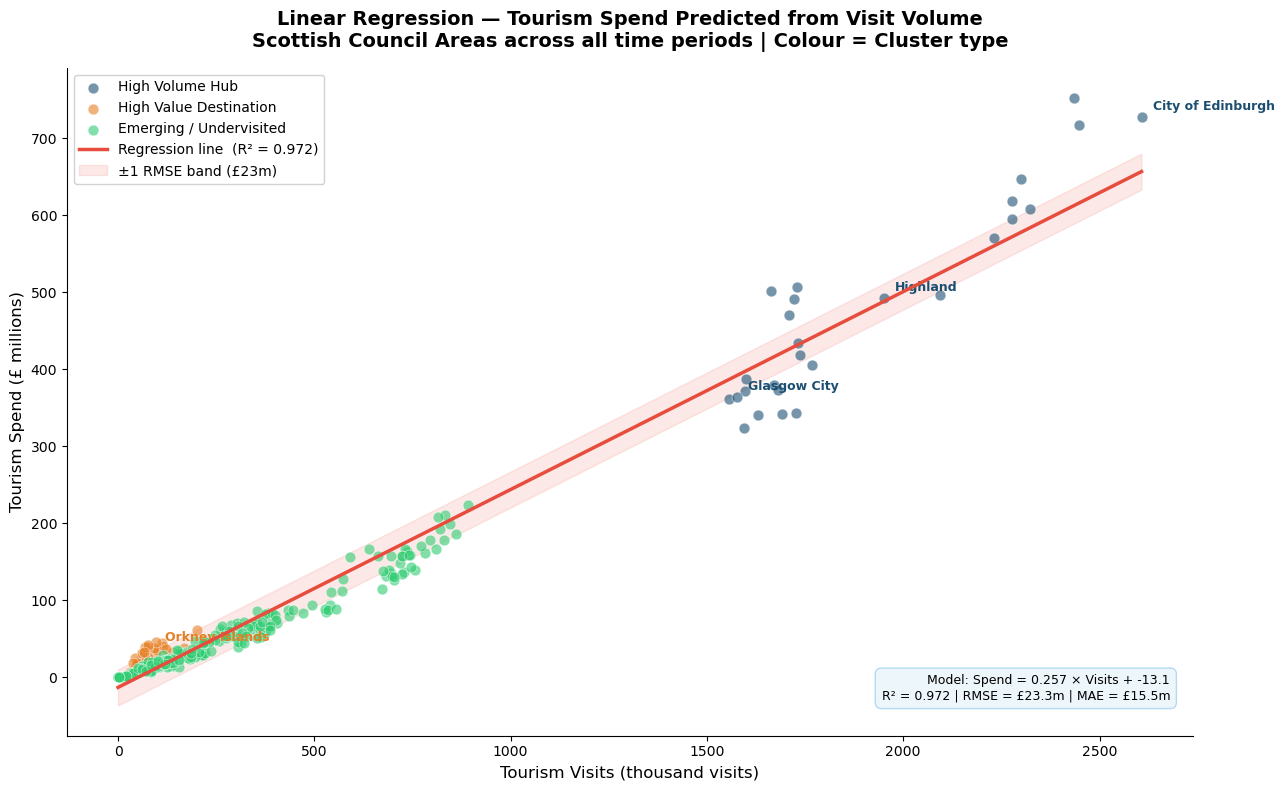

In [53]:
# ============================================================
# FIGURE 13 - Linear Regression Plot
# Shows actual data points and fitted regression line
# Colour coded by cluster type to show how clusters
# relate to the overall regression relationship
# ============================================================

# Add cluster labels to regression dataframe
df_reg_model = pd.merge(
    df_reg_model,
    pivot[['Region', 'Cluster_Label']],
    on='Region',
    how='left'
)

# Regression line points
x_line = np.linspace(
    X_lr.min(), X_lr.max(), 200
).reshape(-1, 1)
y_line = model.predict(x_line)

fig, ax = plt.subplots(figsize=(13, 8))

# Plot data points coloured by cluster
cluster_colours_reg = {
    'High Volume Hub'        : '#1B4F72',
    'High Value Destination' : '#E67E22',
    'Emerging / Undervisited': '#2ECC71'
}

for label, colour in cluster_colours_reg.items():
    mask = df_reg_model['Cluster_Label'] == label
    ax.scatter(
        df_reg_model.loc[mask, 'Visits_m'],
        df_reg_model.loc[mask, 'Spend_£m'],
        color=colour,
        alpha=0.6,
        s=60,
        label=label,
        edgecolors='white',
        linewidths=0.5,
        zorder=3
    )

# Plot regression line
ax.plot(
    x_line, y_line,
    color='#E74C3C',
    linewidth=2.5,
    linestyle='-',
    label=f'Regression line  (R² = {r2:.3f})',
    zorder=4
)

# Confidence band — ±1 RMSE
ax.fill_between(
    x_line.flatten(),
    y_line - rmse,
    y_line + rmse,
    alpha=0.12,
    color='#E74C3C',
    label=f'±1 RMSE band (£{rmse:.0f}m)'
)

# Annotate key regions
key_regions = ['City of Edinburgh', 'Highland',
               'Glasgow City', 'Orkney Islands']
latest_data = df_reg_model[
    df_reg_model['DateCode'] == latest_period
]
for _, row in latest_data.iterrows():
    if row['Region'] in key_regions:
        ax.annotate(
            row['Region'],
            (row['Visits_m'], row['Spend_£m']),
            textcoords='offset points',
            xytext=(8, 5),
            fontsize=9,
            fontweight='bold',
            color=cluster_colours_reg.get(
                row['Cluster_Label'], '#333333')
        )

# Model equation box
equation_text = (
    f"Model: Spend = {model.coef_[0]:.3f} × Visits "
    f"+ {model.intercept_:.1f}\n"
    f"R² = {r2:.3f} | RMSE = £{rmse:.1f}m | "
    f"MAE = £{mae:.1f}m"
)
ax.text(
    0.98, 0.05,
    equation_text,
    transform=ax.transAxes,
    fontsize=9,
    ha='right', va='bottom',
    bbox=dict(
        boxstyle='round,pad=0.5',
        facecolor='#EBF5FB',
        alpha=0.9,
        edgecolor='#AED6F1'
    )
)

ax.set_xlabel('Tourism Visits (thousand visits)', fontsize=12)
ax.set_ylabel('Tourism Spend (£ millions)', fontsize=12)
ax.set_title(
    'Linear Regression — Tourism Spend Predicted from Visit Volume\n'
    'Scottish Council Areas across all time periods | '
    'Colour = Cluster type',
    fontsize=14, fontweight='bold', pad=15
)
ax.legend(fontsize=10, loc='upper left',
          framealpha=0.9, edgecolor='#CCCCCC')
plt.tight_layout()
plt.savefig('chart13_regression.png', dpi=150, bbox_inches='tight')
plt.show()

### Figure 13: Linear Regression - Tourism Spend Predicted from Visit Volume (2009–2019)
**Source:** Scottish Government (2024) - Regional Domestic Tourism

---

**What the chart shows:**
Scatter plot showing all 32 council areas across nine 
time periods (288 data points total) with visit volume 
on the x-axis and tourism spend on the y-axis. Points 
are colour coded by cluster type. The red line shows the 
fitted regression line and the shaded band represents 
plus or minus one RMSE prediction interval.

**Model equation:**
Spend (£m) = 0.257 × Visits − 13.1

**Key finding:**
R² = 0.972 visit volume alone explains 97.2% of the 
variation in regional tourism expenditure. Each additional 
thousand visits generates approximately £257,000 in 
additional spend. Doubling the average emerging region's 
visits from 248,000 to 497,000 would generate approximately 
£63.9 million in additional annual spend.

**What this means:**
The exceptionally strong R² confirms visit volume as the 
primary determinant of regional tourism economic output. 
This provides a quantitative basis for evaluating the 
economic return on regional tourism investment, directly 
supporting Recommendation 1 on regional dispersal and 
Recommendation 5 on differentiated destination management.

**Model limitations:**
- Assumes linear relationship between visits and spend
- Based on pre-2020 data only
- Single independent variable model
- Does not account for visitor type or seasonality

In [54]:
# ============================================================
# Use the model to make predictions
# Shows practical application of the regression model
# ============================================================

print("REGRESSION MODEL — PRACTICAL PREDICTIONS")
print("=" * 55)

# Predict spend for different visit volumes
visit_scenarios = [100, 250, 500, 1000, 1500, 2000, 2607]
print("\nPredicted spend for given visit volumes:")
print(f"{'Visits (000s)':<20} {'Predicted Spend':<20} {'Scenario'}")
print("-" * 60)
for visits in visit_scenarios:
    predicted = model.predict([[visits]])[0]
    if visits == 100:
        scenario = "Small council area"
    elif visits == 250:
        scenario = "Avg emerging region"
    elif visits == 500:
        scenario = "Mid-tier region"
    elif visits == 1000:
        scenario = "Strong regional hub"
    elif visits == 1500:
        scenario = "Glasgow City level"
    elif visits == 2000:
        scenario = "Highland level"
    else:
        scenario = "Edinburgh level"
    print(f"{visits:<20} £{predicted:<18.1f} {scenario}")

print(f"\nModel insight for VisitScotland:")
print(f"  If an Emerging region doubled its visits")
spend_increase = model.coef_[0] * 248.65
print(f"  from avg 248k to 497k visits,")
print(f"  predicted spend increase = £{spend_increase:.1f}m")
print(f"\n  This quantifies the economic return on")
print(f"  investment in regional tourism development")

print(f"\nModel limitations:")
print(f"  - Linear model assumes constant relationship")
print(f"  - Does not account for visitor type or season")
print(f"  - Data covers 2009-2019 rolling averages only")
print(f"  - R²={r2:.3f} means {(1-r2)*100:.1f}% of variation")
print(f"    is explained by other factors not in model")

REGRESSION MODEL — PRACTICAL PREDICTIONS

Predicted spend for given visit volumes:
Visits (000s)        Predicted Spend      Scenario
------------------------------------------------------------
100                  £12.6               Small council area
250                  £51.1               Avg emerging region
500                  £115.4              Mid-tier region
1000                 £243.8              Strong regional hub
1500                 £372.3              Glasgow City level
2000                 £500.8              Highland level
2607                 £656.7              Edinburgh level

Model insight for VisitScotland:
  If an Emerging region doubled its visits
  from avg 248k to 497k visits,
  predicted spend increase = £63.9m

  This quantifies the economic return on
  investment in regional tourism development

Model limitations:
  - Linear model assumes constant relationship
  - Does not account for visitor type or season
  - Data covers 2009-2019 rolling averages onl